# Exploring the LILA BLACK player data

We want to understand the data before designing database tables.
Work through this notebook from top to bottom. Each section asks one question.

Spark loads and analyses all event rows. Pandas is only used for file metadata,
small charts, and one selected match. No source records are changed or removed.

Choose this project's `.venv` Python kernel. Run from the project folder.
All exploration code and its output labels are contained in this notebook.
Java 17 or newer is needed for Spark.

> **IMPORTANT — THIS INVESTIGATION DID NOT ESTABLISH A UNIVERSAL KILLER–VICTIM RULE.**
>
> We tested whether matching kill/death timestamps and the end of recorded movement could identify who killed whom. The notebook records the idea we attempted to test, the evidence supporting particular candidate pairs, and the limitations that prevent treating it as established fact.
>
> **The 82 matched-pair results and the 105 changed-coordinate death cases come from different checks. The 105 cases are not exceptions inside the 82 matched pairs.** A consolidated explanation appears under **“Kill-attribution investigation — what we tried and what we learned”** near the end.

## 1. Start Spark and find the data

In [1]:
from pathlib import Path
import os
import sys
import hashlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as parquet
from PIL import Image
from IPython.display import display
from pyspark.sql import SparkSession, Window
from pyspark.sql import functions as F

# F is the standard alias for Spark's built-in column functions.
# Local Spark needs a localhost address and the same Python as this notebook.
os.environ["SPARK_LOCAL_IP"] = "127.0.0.1"
os.environ["PYSPARK_PYTHON"] = sys.executable

In [2]:
spark = (
    SparkSession.builder
    .master("local[2]")
    .appName("LILA data exploration")
    .config("spark.ui.enabled", "false")
    .config("spark.ui.showConsoleProgress", "false")
    .config("spark.sql.shuffle.partitions", "8")
    .config("spark.sql.session.timeZone", "UTC")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")

print("Spark version:", spark.version)
print("Python:", sys.executable)

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/05 02:20:09 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark version: 4.3.0
Python: /Users/mskbaruah/Documents/ChatGPT/LILA games/.venv/bin/python


In [3]:
project_folder = Path.cwd().resolve()
while not (project_folder / "player_data").is_dir():
    if project_folder == project_folder.parent:
        raise FileNotFoundError("Open this notebook inside the LILA games project folder.")
    project_folder = project_folder.parent
data_folder = project_folder / "player_data"

if not data_folder.is_dir():
    raise FileNotFoundError("Open this notebook from the LILA games project folder.")

parquet_files = sorted(data_folder.glob("February_*/*.nakama-0"))

if not parquet_files:
    raise FileNotFoundError("No .nakama-0 files were found.")

print("Files found:", len(parquet_files))
print("First file:", parquet_files[0].relative_to(data_folder))

Files found: 1243
First file: February_10/0019c582-574d-4a53-9f77-554519b75b4c_1298e3e2-2776-4038-ba9b-72808b041561.nakama-0


## 2. What is in each file?

These are Parquet files even though their names do not end in `.parquet`.
Use PyArrow to inspect each file's metadata and original timestamp order.
Spark does not guarantee source row order, so this particular check belongs here.
Any unreadable file stops the notebook with its filename.

In [4]:
file_details = []

for file_path in parquet_files:
    try:
        player_file = parquet.ParquetFile(file_path)
        file_timestamps = player_file.read(columns=["ts"])
        timestamp_values = file_timestamps["ts"].cast(pa.int64()).to_pylist()

        backwards_steps = 0
        for row_number in range(1, len(timestamp_values)):
            previous_time = timestamp_values[row_number - 1]
            current_time = timestamp_values[row_number]
            if previous_time is not None and current_time is not None:
                if current_time < previous_time:
                    backwards_steps += 1

        compression_types = set()
        for group_number in range(player_file.metadata.num_row_groups):
            row_group = player_file.metadata.row_group(group_number)
            for column_number in range(row_group.num_columns):
                compression_types.add(row_group.column(column_number).compression)

        file_details.append({
            "source_file": str(file_path.relative_to(data_folder)),
            "collection_folder": file_path.parent.name,
            "rows": player_file.metadata.num_rows,
            "file_bytes": file_path.stat().st_size,
            "row_groups": player_file.metadata.num_row_groups,
            "schema": str(player_file.schema_arrow.remove_metadata()),
            "compression": ", ".join(sorted(compression_types)),
            "backwards_steps": backwards_steps,
            "file_hash": hashlib.sha256(file_path.read_bytes()).hexdigest(),
        })
    except Exception as error:
        raise RuntimeError(f"Could not read {file_path}") from error

file_inventory = pd.DataFrame(file_details)

In [5]:
files_by_day = file_inventory.groupby("collection_folder").agg(
    files=("source_file", "count"),
    rows=("rows", "sum"),
    file_bytes=("file_bytes", "sum"),
)
print("\nFiles, event rows, and file sizes for each collection day:")
display(files_by_day)
print("\nSummary statistics for file row counts, sizes, and row groups:")
display(file_inventory[["rows", "file_bytes", "row_groups"]].describe())

print("Different file schemas:", file_inventory["schema"].nunique())
print("Repeated file hashes:", file_inventory["file_hash"].duplicated().sum())
print("Compression:", file_inventory["compression"].unique())
print("\nParquet schema of the first source file:")
print(parquet.read_schema(parquet_files[0]))

files_needing_sorting = file_inventory[file_inventory["backwards_steps"] > 0]
print("\nSource files whose timestamps are not in chronological order (empty means none):")
display(files_needing_sorting[["source_file", "backwards_steps"]])


Files, event rows, and file sizes for each collection day:


,files,rows,file_bytes
collection_folder,,,
February_10,437,33687,2991430
February_11,293,21235,1992563
February_12,268,18429,1783860
February_13,166,11106,1103813
February_14,79,4647,499545



Summary statistics for file row counts, sizes, and row groups:


,rows,file_bytes,row_groups
count,1243.000000,1243.000000,1243.0
mean,71.684634,6734.683025,1.0
std,45.366324,1006.084298,0.0
min,2.000000,3146.000000,1.0
25%,34.000000,5947.500000,1.0
50%,61.000000,6656.000000,1.0
75%,100.000000,7449.500000,1.0
max,294.000000,10806.000000,1.0


Different file schemas: 1
Repeated file hashes: 1
Compression: ['SNAPPY']

Parquet schema of the first source file:
user_id: string not null
  -- field metadata --
  PARQUET:field_id: '0'
match_id: string not null
  -- field metadata --
  PARQUET:field_id: '0'
map_id: string not null
  -- field metadata --
  PARQUET:field_id: '0'
x: float not null
  -- field metadata --
  PARQUET:field_id: '0'
y: float not null
  -- field metadata --
  PARQUET:field_id: '0'
z: float not null
  -- field metadata --
  PARQUET:field_id: '0'
ts: timestamp[ms] not null
  -- field metadata --
  PARQUET:field_id: '0'
event: binary not null
  -- field metadata --
  PARQUET:field_id: '0'

Source files whose timestamps are not in chronological order (empty means none):


,source_file,backwards_steps
231,February_10/688cb2e4-2215-4b3b-9af1-a6ee71d176...,1
304,February_10/94d042cb-a0f2-45f3-bdca-42fab73cfe...,1
695,February_11/db454a35-d216-4379-b140-2931160c7d...,1


## 3. Load every day into one Spark DataFrame

Keep `raw_events` unchanged. Create `events` with readable names and a few
additional fields. A filename or folder is provenance, not an event identifier.

In [6]:
raw_events = (
    spark.read
    .option("recursiveFileLookup", "true")
    .option("pathGlobFilter", "*.nakama-0")
    .option("mergeSchema", "true")
    .parquet(str(data_folder))
)
print("\nSchema of the complete raw Spark dataset:")
raw_events.printSchema()
print("\nFive sample raw event rows:")
raw_events.show(5, truncate=False)


Schema of the complete raw Spark dataset:
root
 |-- user_id: string (nullable = true)
 |-- match_id: string (nullable = true)
 |-- map_id: string (nullable = true)
 |-- x: float (nullable = true)
 |-- y: float (nullable = true)
 |-- z: float (nullable = true)
 |-- ts: timestamp_ntz (nullable = true)
 |-- event: binary (nullable = true)


Five sample raw event rows:


+------------------------------------+---------------------------------------------+-------------+---------+----------+----------+-----------------------+-------------------------+
|user_id                             |match_id                                     |map_id       |x        |y         |z         |ts                     |event                    |
+------------------------------------+---------------------------------------------+-------------+---------+----------+----------+-----------------------+-------------------------+
|94d042cb-a0f2-45f3-bdca-42fab73cfef5|d3a3297e-2cdf-4a49-8450-09119b91a779.nakama-0|AmbroseValley|266.9803 |110.418724|-44.796886|1970-01-21 11:52:02.175|[50 6F 73 69 74 69 6F 6E]|
|94d042cb-a0f2-45f3-bdca-42fab73cfef5|d3a3297e-2cdf-4a49-8450-09119b91a779.nakama-0|AmbroseValley|245.96773|110.09972 |-26.014303|1970-01-21 11:52:02.205|[50 6F 73 69 74 69 6F 6E]|
|94d042cb-a0f2-45f3-bdca-42fab73cfef5|d3a3297e-2cdf-4a49-8450-09119b91a779.nakama-0|AmbroseVall

In [7]:
events = raw_events.withColumn("source_location", F.input_file_name())
events = events.withColumn(
    "source_file",
    F.regexp_extract("source_location", r"player_data/(.*)$", 1),
)
events = events.withColumn(
    "source_filename",
    F.regexp_extract("source_file", r"([^/]+)$", 1),
)
events = events.withColumn(
    "collection_day",
    F.regexp_extract("source_file", r"February_(\d+)", 1),
)

# The README supplies the year and month; the folder supplies the day.
events = events.withColumn(
    "collection_date",
    F.to_date(F.concat(F.lit("2026-02-"), F.col("collection_day")), "yyyy-MM-dd"),
)
events = events.withColumnRenamed("event", "event_bytes")
events = events.withColumn("event", F.decode("event_bytes", "UTF-8"))

# Preserve the stored timestamp and its integer value before interpreting units.
events = events.withColumn("timestamp_value", F.unix_millis("ts"))

In [8]:
uuid_pattern = (
    r"^[0-9a-fA-F]{8}-[0-9a-fA-F]{4}-[0-9a-fA-F]{4}-"
    r"[0-9a-fA-F]{4}-[0-9a-fA-F]{12}$"
)

# Actor identity comes from the ID format, not from names such as BotKill.
events = events.withColumn(
    "actor_type",
    F.when(F.col("user_id").rlike(r"^\d+$"), "bot")
    .when(F.col("user_id").rlike(uuid_pattern), "human")
    .otherwise("unknown"),
)
events = events.cache()

total_event_rows = events.count()
expected_event_rows = int(file_inventory["rows"].sum())
assert total_event_rows == expected_event_rows

print("Rows loaded into Spark:", total_event_rows)
print("\nEight decoded event rows with source files, actor types, and raw timestamps:")
events.select(
    "source_file", "user_id", "match_id", "map_id",
    "event", "actor_type", "ts", "timestamp_value",
).orderBy("source_file", "timestamp_value").show(8, truncate=False)

Rows loaded into Spark: 89104

Eight decoded event rows with source files, actor types, and raw timestamps:


+----------------------------------------------------------------------------------------------+------------------------------------+---------------------------------------------+-------------+--------+----------+-----------------------+---------------+
|source_file                                                                                   |user_id                             |match_id                                     |map_id       |event   |actor_type|ts                     |timestamp_value|
+----------------------------------------------------------------------------------------------+------------------------------------+---------------------------------------------+-------------+--------+----------+-----------------------+---------------+
|February_10/0019c582-574d-4a53-9f77-554519b75b4c_1298e3e2-2776-4038-ba9b-72808b041561.nakama-0|0019c582-574d-4a53-9f77-554519b75b4c|1298e3e2-2776-4038-ba9b-72808b041561.nakama-0|AmbroseValley|Position|human     |1970-01-21 11:52:34.537|1

## 4. Are any fields missing or invalid?

We check values first, then compare the record IDs with their filenames.
Empty result tables below mean no exceptions were found.

In [9]:
required_columns = [
    "user_id", "match_id", "map_id", "x", "y", "z", "ts", "event", "collection_date",
]
null_counts = []

for column_name in required_columns:
    missing_value = F.when(F.col(column_name).isNull(), 1).otherwise(0)
    null_counts.append(F.sum(missing_value).alias(column_name))

print("\nNumber of missing values in each required column:")
events.select(*null_counts).show()

coordinate_checks = []
for column_name in ["x", "y", "z"]:
    coordinate = F.col(column_name)
    invalid_number = F.isnan(coordinate) | (F.abs(coordinate) == float("inf"))
    invalid_count = F.sum(F.when(invalid_number, 1).otherwise(0))
    coordinate_checks.append(invalid_count.alias(column_name))

print("\nNumber of NaN or infinite values in each coordinate column:")
events.select(*coordinate_checks).show()
print("\nSample events with an unrecognized actor ID format (empty means none):")
events.filter(F.col("actor_type") == "unknown").show(5)


Number of missing values in each required column:


+-------+--------+------+---+---+---+---+-----+---------------+
|user_id|match_id|map_id|  x|  y|  z| ts|event|collection_date|
+-------+--------+------+---+---+---+---+-----+---------------+
|      0|       0|     0|  0|  0|  0|  0|    0|              0|
+-------+--------+------+---+---+---+---+-----+---------------+


Number of NaN or infinite values in each coordinate column:
+---+---+---+
|  x|  y|  z|
+---+---+---+
|  0|  0|  0|
+---+---+---+


Sample events with an unrecognized actor ID format (empty means none):


+-------+--------+------+---+---+---+---+-----------+---------------+-----------+---------------+--------------+---------------+-----+---------------+----------+
|user_id|match_id|map_id|  x|  y|  z| ts|event_bytes|source_location|source_file|source_filename|collection_day|collection_date|event|timestamp_value|actor_type|
+-------+--------+------+---+---+---+---+-----------+---------------+-----------+---------------+--------------+---------------+-----+---------------+----------+
+-------+--------+------+---+---+---+---+-----------+---------------+-----------+---------------+--------------+---------------+-----+---------------+----------+



In [10]:
known_events = [
    "Position", "BotPosition", "Kill", "Killed",
    "BotKill", "BotKilled", "KilledByStorm", "Loot",
]
known_maps = ["AmbroseValley", "GrandRift", "Lockdown"]

print("\nSample events whose labels are not listed in the README (empty means none):")
events.filter(~F.col("event").isin(known_events)).show(5)
print("\nSample events with an unknown map ID (empty means none):")
events.filter(~F.col("map_id").isin(known_maps)).show(5)

filename_checks = events.withColumn(
    "filename_user_id", F.split("source_filename", "_").getItem(0),
)
filename_checks = filename_checks.withColumn(
    "filename_match_id", F.split("source_filename", "_").getItem(1),
)
filename_mismatches = filename_checks.filter(
    (F.col("user_id") != F.col("filename_user_id"))
    | (F.col("match_id") != F.col("filename_match_id"))
)
print("\nRecords whose actor or match ID disagrees with the filename (empty means none):")
filename_mismatches.select("source_file", "user_id", "match_id").show(10, truncate=False)


Sample events whose labels are not listed in the README (empty means none):


+-------+--------+------+---+---+---+---+-----------+---------------+-----------+---------------+--------------+---------------+-----+---------------+----------+
|user_id|match_id|map_id|  x|  y|  z| ts|event_bytes|source_location|source_file|source_filename|collection_day|collection_date|event|timestamp_value|actor_type|
+-------+--------+------+---+---+---+---+-----------+---------------+-----------+---------------+--------------+---------------+-----+---------------+----------+
+-------+--------+------+---+---+---+---+-----------+---------------+-----------+---------------+--------------+---------------+-----+---------------+----------+


Sample events with an unknown map ID (empty means none):
+-------+--------+------+---+---+---+---+-----------+---------------+-----------+---------------+--------------+---------------+-----+---------------+----------+
|user_id|match_id|map_id|  x|  y|  z| ts|event_bytes|source_location|source_file|source_filename|collection_day|collection_date|eve

+-----------+-------+--------+
|source_file|user_id|match_id|
+-----------+-------+--------+
+-----------+-------+--------+



In [11]:
source_file_summary = events.groupBy("source_file").agg(
    F.count("*").alias("event_rows"),
    F.countDistinct("user_id").alias("actors"),
    F.countDistinct("match_id").alias("matches"),
    F.countDistinct("map_id").alias("maps"),
)

# A source file is documented as one actor in one match on one map.
unexpected_files = source_file_summary.filter(
    (F.col("actors") != 1) | (F.col("matches") != 1) | (F.col("maps") != 1)
)
print("\nFiles containing more or fewer than one actor, match, or map (empty means none):")
unexpected_files.show(10, truncate=False)


Files containing more or fewer than one actor, match, or map (empty means none):


+-----------+----------+------+-------+----+
|source_file|event_rows|actors|matches|maps|
+-----------+----------+------+-------+----+
+-----------+----------+------+-------+----+



## 5. How much data do we have for each map and day?

These are recorded participants, not complete lobbies. February 14 is partial.
A journey means one distinct `(match_id, user_id)` pair, not one file.

In [12]:
dataset_summary = events.agg(
    F.count("*").alias("event_rows"),
    F.countDistinct("source_file").alias("files"),
    F.countDistinct("match_id").alias("matches"),
    F.countDistinct("user_id").alias("raw_actor_ids"),
    F.countDistinct(F.struct("match_id", "user_id")).alias("journeys"),
    F.countDistinct("map_id").alias("maps"),
)
print("\nDataset totals: event rows, source files, matches, raw actor IDs, journeys, and maps:")
dataset_summary.show()

coverage_by_day = events.groupBy("collection_date", "map_id").agg(
    F.count("*").alias("event_rows"),
    F.countDistinct("match_id").alias("matches"),
    F.countDistinct(F.struct("match_id", "user_id")).alias("journeys"),
)
print("\nRecorded events, matches, and journeys for each collection date and map:")
coverage_by_day.orderBy("collection_date", "map_id").show(30)


Dataset totals: event rows, source files, matches, raw actor IDs, journeys, and maps:


+----------+-----+-------+-------------+--------+----+
|event_rows|files|matches|raw_actor_ids|journeys|maps|
+----------+-----+-------+-------------+--------+----+
|     89104| 1243|    796|          339|    1242|   3|
+----------+-----+-------+-------------+--------+----+


Recorded events, matches, and journeys for each collection date and map:


+---------------+-------------+----------+-------+--------+
|collection_date|       map_id|event_rows|matches|journeys|
+---------------+-------------+----------+-------+--------+
|     2026-02-10|AmbroseValley|     23720|    200|     315|
|     2026-02-10|    GrandRift|      2154|     24|      28|
|     2026-02-10|     Lockdown|      7813|     61|      94|
|     2026-02-11|AmbroseValley|     13771|    138|     198|
|     2026-02-11|    GrandRift|      1796|     13|      24|
|     2026-02-11|     Lockdown|      5668|     50|      71|
|     2026-02-12|AmbroseValley|     12557|    127|     177|
|     2026-02-12|    GrandRift|       804|      9|       9|
|     2026-02-12|     Lockdown|      5068|     26|      82|
|     2026-02-13|AmbroseValley|      7727|     78|     103|
|     2026-02-13|    GrandRift|      1053|      5|      20|
|     2026-02-13|     Lockdown|      2326|     29|      43|
|     2026-02-14|AmbroseValley|      3238|     24|      44|
|     2026-02-14|    GrandRift|      104

In [13]:
actors_by_type = events.groupBy("actor_type").agg(
    F.countDistinct("user_id").alias("raw_actor_ids"),
    F.countDistinct(F.struct("match_id", "user_id")).alias("journeys"),
    F.count("*").alias("event_rows"),
)
print("\nRaw actor IDs, recorded journeys, and event rows for humans and bots:")
actors_by_type.show()

event_counts = events.groupBy("event").count()
event_counts = event_counts.withColumn(
    "percent_of_rows", F.round(F.col("count") * 100 / total_event_rows, 2),
)
print("\nEvent counts and their percentage of all recorded rows:")
event_counts.orderBy(F.desc("count")).show()

events_by_actor = events.groupBy("event").pivot("actor_type", ["human", "bot"]).count()
print("\nEvent counts split between human and bot IDs:")
events_by_actor.fillna(0).orderBy("event").show()


Raw actor IDs, recorded journeys, and event rows for humans and bots:


+----------+-------------+--------+----------+
|actor_type|raw_actor_ids|journeys|event_rows|
+----------+-------------+--------+----------+
|     human|          245|     781|     66161|
|       bot|           94|     461|     22943|
+----------+-------------+--------+----------+


Event counts and their percentage of all recorded rows:


+-------------+-----+---------------+
|        event|count|percent_of_rows|
+-------------+-----+---------------+
|     Position|51347|          57.63|
|  BotPosition|21712|          24.37|
|         Loot|12885|          14.46|
|      BotKill| 2415|           2.71|
|    BotKilled|  700|           0.79|
|KilledByStorm|   39|           0.04|
|         Kill|    3|            0.0|
|       Killed|    3|            0.0|
+-------------+-----+---------------+


Event counts split between human and bot IDs:


+-------------+-----+-----+
|        event|human|  bot|
+-------------+-----+-----+
|      BotKill| 2232|  183|
|    BotKilled|  403|  297|
|  BotPosition|    0|21712|
|         Kill|    3|    0|
|       Killed|    3|    0|
|KilledByStorm|   39|    0|
|         Loot|12770|  115|
|     Position|50711|  636|
+-------------+-----+-----+



### Key totals and human/bot breakdown

These totals count **recorded event rows**, including repeated payloads. They are not deduplicated gameplay incidents.

- **Events:** all rows.
- **Steps:** the dataset has position samples, not physical footsteps. Here, movement samples means `Position` plus `BotPosition`. The movement section later counts the intervals between those samples separately.
- **Kills:** rows labelled `Kill` or `BotKill`. This is a label-based total, not a verified count of unique kills.
- **Loot:** rows labelled `Loot`. Item identities and quantities are absent, so these are pickup-event rows, not necessarily distinct items.

Actor type comes from the user ID format. Both movement labels are included for both actor types because some numeric bot IDs have `Position` rows.

In [14]:
total_movement_samples = events.filter(
    F.col("event").isin("Position", "BotPosition")
).count()
total_kill_label_rows = events.filter(
    F.col("event").isin("Kill", "BotKill")
).count()
total_loot_rows = events.filter(F.col("event") == "Loot").count()
total_storm_death_rows = events.filter(F.col("event") == "KilledByStorm").count()

print("Dataset totals, counting recorded rows without deduplication:")
print(f"Total events: {total_event_rows:,}")
print(f"Total movement samples (recorded positions, not physical footsteps): {total_movement_samples:,}")
print(f"Total kill-labelled rows (Kill + BotKill): {total_kill_label_rows:,}")
print(f"Total loot-event rows: {total_loot_rows:,}")
print(f"Total storm-death-labelled rows: {total_storm_death_rows:,}")

Dataset totals, counting recorded rows without deduplication:
Total events: 89,104
Total movement samples (recorded positions, not physical footsteps): 73,059
Total kill-labelled rows (Kill + BotKill): 2,418
Total loot-event rows: 12,885
Total storm-death-labelled rows: 39


In [15]:
human_events = events.filter(F.col("actor_type") == "human")
bot_events = events.filter(F.col("actor_type") == "bot")

human_movement_samples = human_events.filter(
    F.col("event").isin("Position", "BotPosition")
).count()
bot_movement_samples = bot_events.filter(
    F.col("event").isin("Position", "BotPosition")
).count()
human_loot_rows = human_events.filter(F.col("event") == "Loot").count()
bot_loot_rows = bot_events.filter(F.col("event") == "Loot").count()

print("Movement-sample and loot-event totals, classified by recorded actor ID:")
print(f"Movement samples recorded under human IDs: {human_movement_samples:,}")
print(f"Movement samples recorded under bot IDs: {bot_movement_samples:,}")
print(f"Loot-event rows recorded under human IDs: {human_loot_rows:,}")
print(f"Loot-event rows recorded under bot IDs: {bot_loot_rows:,}")

Movement-sample and loot-event totals, classified by recorded actor ID:
Movement samples recorded under human IDs: 50,711
Movement samples recorded under bot IDs: 22,348
Loot-event rows recorded under human IDs: 12,770
Loot-event rows recorded under bot IDs: 115


### Combat totals that require an interpretation

The README describes `BotKilled` as a human killed by a bot and `BotKill` as a human killing a bot. Under that reading, **human-ID `BotKilled` rows** are a proxy for humans killed by bots, and **human-ID `BotKill` rows** are a proxy for bots killed by humans.

However, the README also claims bots generate these labels, and both labels occur under both actor types. There are no explicit killer/victim columns. We therefore display these requested metrics as **README-based proxies**, not confirmed unique victims. We show the corresponding bot-ID label counts separately; do not add them to the human-ID proxies, since the relationship and potential overlap are unknown.

In [16]:
human_botkilled_rows = human_events.filter(F.col("event") == "BotKilled").count()
human_botkill_rows = human_events.filter(F.col("event") == "BotKill").count()
bot_botkilled_rows = bot_events.filter(F.col("event") == "BotKilled").count()
bot_botkill_rows = bot_events.filter(F.col("event") == "BotKill").count()

print("Requested combat breakdown under the README's human-event interpretation:")
print(f"Humans killed by bots — human BotKilled rows (proxy): {human_botkilled_rows:,}")
print(f"Bots killed by humans — human BotKill rows (proxy): {human_botkill_rows:,}")

print("\nBot-ID rows shown separately for attribution checks; do not add these to the proxies:")
print(f"BotKilled rows recorded under bot IDs: {bot_botkilled_rows:,}")
print(f"BotKill rows recorded under bot IDs: {bot_botkill_rows:,}")
print("These counts are recorded event labels, not verified distinct victims or combat incidents.")

Requested combat breakdown under the README's human-event interpretation:
Humans killed by bots — human BotKilled rows (proxy): 403
Bots killed by humans — human BotKill rows (proxy): 2,232

Bot-ID rows shown separately for attribution checks; do not add these to the proxies:
BotKilled rows recorded under bot IDs: 297
BotKill rows recorded under bot IDs: 183
These counts are recorded event labels, not verified distinct victims or combat incidents.



Chart of recorded event counts by collection day and map:


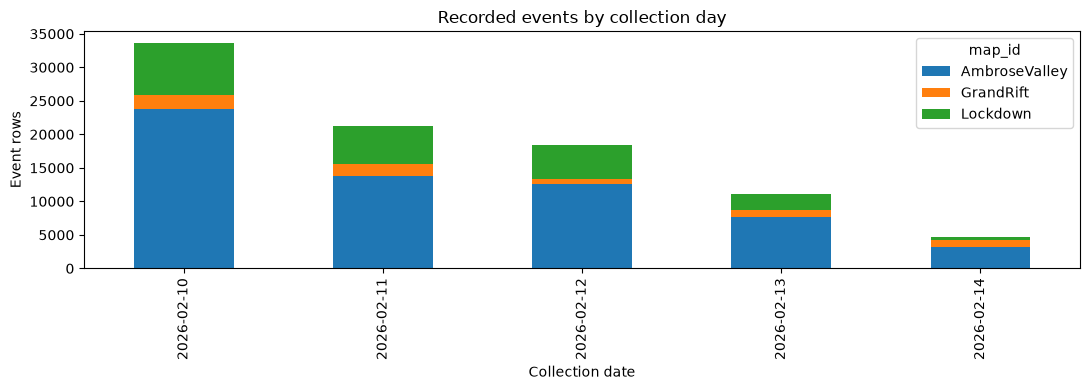

In [17]:
# Collect only the small day/map summary for this chart.
daily_chart_data = coverage_by_day.orderBy("collection_date", "map_id").toPandas()
daily_chart_data = daily_chart_data.pivot(
    index="collection_date", columns="map_id", values="event_rows",
)
daily_chart_data.plot.bar(stacked=True, figsize=(11, 4))
plt.title("Recorded events by collection day")
plt.ylabel("Event rows")
plt.xlabel("Collection date")
plt.tight_layout()
print("\nChart of recorded event counts by collection day and map:")
plt.show()

## 6. How are matches, journeys, and files related?

Build two summaries we can reuse: one row per recorded journey, and one row
per match. Test whether a journey spans files and whether a match spans maps
or collection dates before choosing foreign keys.

In [18]:
player_journeys = events.groupBy("match_id", "user_id", "actor_type").agg(
    F.count("*").alias("event_rows"),
    F.countDistinct("source_file").alias("source_files"),
    F.countDistinct("collection_date").alias("collection_dates"),
    F.min("timestamp_value").alias("first_timestamp"),
    F.max("timestamp_value").alias("last_timestamp"),
)
player_journeys = player_journeys.withColumn(
    "recorded_span", F.col("last_timestamp") - F.col("first_timestamp"),
)
player_journeys = player_journeys.cache()

match_summary = events.groupBy("match_id").agg(
    F.first("map_id").alias("map_id"),
    F.countDistinct("map_id").alias("map_count"),
    F.countDistinct("collection_date").alias("collection_dates"),
    F.countDistinct("user_id").alias("recorded_actors"),
    F.countDistinct(F.when(F.col("actor_type") == "human", F.col("user_id"))).alias("recorded_humans"),
    F.countDistinct(F.when(F.col("actor_type") == "bot", F.col("user_id"))).alias("recorded_bots"),
    F.count("*").alias("event_rows"),
    F.min("timestamp_value").alias("first_timestamp"),
    F.max("timestamp_value").alias("last_timestamp"),
)
match_summary = match_summary.withColumn(
    "recorded_span", F.col("last_timestamp") - F.col("first_timestamp"),
)
match_summary = match_summary.cache()

In [19]:
print("\nNumber of matches for each recorded participant count:")
match_summary.groupBy("recorded_actors").count().orderBy("recorded_actors").show()
print("\nTen matches with the most recorded participants:")
match_summary.orderBy(F.desc("recorded_actors"), "match_id").show(10, truncate=False)

print("Matches on multiple maps:")
match_summary.filter(F.col("map_count") > 1).show(truncate=False)

print("Matches in multiple collection dates:")
match_summary.filter(F.col("collection_dates") > 1).show(truncate=False)

print("Journeys with multiple files:")
player_journeys.filter(F.col("source_files") > 1).show(truncate=False)


Number of matches for each recorded participant count:


+---------------+-----+
|recorded_actors|count|
+---------------+-----+
|              1|  743|
|              2|    1|
|              5|    2|
|              7|   24|
|              8|    8|
|             12|    4|
|             14|    4|
|             15|    9|
|             16|    1|
+---------------+-----+


Ten matches with the most recorded participants:
+---------------------------------------------+-------------+---------+----------------+---------------+---------------+-------------+----------+---------------+--------------+-------------+
|match_id                                     |map_id       |map_count|collection_dates|recorded_actors|recorded_humans|recorded_bots|event_rows|first_timestamp|last_timestamp|recorded_span|
+---------------------------------------------+-------------+---------+----------------+---------------+---------------+-------------+----------+---------------+--------------+-------------+
|fbbc5d02-dd79-42fb-bba5-d768023891c8.nakama-0|AmbroseValley|1  

+---------------------------------------------+------------------------------------+----------+----------+------------+----------------+---------------+--------------+-------------+
|match_id                                     |user_id                             |actor_type|event_rows|source_files|collection_dates|first_timestamp|last_timestamp|recorded_span|
+---------------------------------------------+------------------------------------+----------+----------+------------+----------------+---------------+--------------+-------------+
|ac049b28-8116-4ff1-9e60-4be0537b8cc9.nakama-0|cfa03e9f-81f6-41ef-a0fa-30c7e830f4ed|human     |176       |2           |2               |1770767465     |1770767797    |332          |
+---------------------------------------------+------------------------------------+----------+----------+------------+----------------+---------------+--------------+-------------+



### What events occur in the 743 matches with one recorded participant?

Use the supplied rows directly. Select matches with one distinct `user_id`, then inspect every event in those matches. A row has one actor ID; the schema does not require a separate recording for an opponent before a kill label can appear. Count the observed labels rather than assuming one recorded participant means there are no combat events.

In [20]:
single_participant_matches = match_summary.filter(
    F.col("recorded_actors") == 1
).select("match_id")

single_participant_events = events.join(
    single_participant_matches, on="match_id", how="inner"
)

print("Matches with one recorded participant: event totals and human/bot coverage:")
single_participant_events.groupBy("actor_type").agg(
    F.countDistinct("match_id").alias("matches"),
    F.countDistinct("user_id").alias("raw_actor_ids"),
    F.count("*").alias("event_rows"),
).show()

print("Event labels present in those matches, with row counts and number of affected matches:")
single_participant_event_counts = single_participant_events.groupBy("event").agg(
    F.count("*").alias("event_rows"),
    F.countDistinct("match_id").alias("matches_with_event"),
)
single_participant_event_counts.orderBy("event").show()

Matches with one recorded participant: event totals and human/bot coverage:


+----------+-------+-------------+----------+
|actor_type|matches|raw_actor_ids|event_rows|
+----------+-------+-------------+----------+
|     human|    743|          238|     62993|
+----------+-------+-------------+----------+

Event labels present in those matches, with row counts and number of affected matches:


+-------------+----------+------------------+
|        event|event_rows|matches_with_event|
+-------------+----------+------------------+
|      BotKill|      2119|               556|
|    BotKilled|       379|               378|
|         Kill|         3|                 3|
|       Killed|         3|                 3|
|KilledByStorm|        39|                39|
|         Loot|     12194|               692|
|     Position|     48256|               743|
+-------------+----------+------------------+



In [21]:
single_match_activity = single_participant_events.agg(
    F.countDistinct("match_id").alias("total_matches"),
    F.countDistinct(
        F.when(F.col("event").isin("Kill", "BotKill"), F.col("match_id"))
    ).alias("matches_with_kill_labels"),
    F.countDistinct(
        F.when(F.col("event") == "Loot", F.col("match_id"))
    ).alias("matches_with_loot"),
    F.countDistinct(
        F.when(F.col("event") == "KilledByStorm", F.col("match_id"))
    ).alias("matches_with_storm_deaths"),
)
print("How many of the one-recorded-participant matches contain kill labels, loot, or storm deaths:")
single_match_activity.show()

How many of the one-recorded-participant matches contain kill labels, loot, or storm deaths:


+-------------+------------------------+-----------------+-------------------------+
|total_matches|matches_with_kill_labels|matches_with_loot|matches_with_storm_deaths|
+-------------+------------------------+-----------------+-------------------------+
|          743|                     556|              692|                       39|
+-------------+------------------------+-----------------+-------------------------+



In [22]:
single_match_event_breakdown = (
    single_participant_events
    .groupBy("match_id", "user_id", "actor_type")
    .pivot("event", known_events)
    .count()
    .fillna(0)
)

print("Three concrete one-recorded-participant matches with combat and loot event counts:")
single_match_event_breakdown.orderBy(
    F.desc("BotKill"), F.desc("Loot"), "match_id"
).show(3, truncate=False)

Three concrete one-recorded-participant matches with combat and loot event counts:


+---------------------------------------------+------------------------------------+----------+--------+-----------+----+------+-------+---------+-------------+----+
|match_id                                     |user_id                             |actor_type|Position|BotPosition|Kill|Killed|BotKill|BotKilled|KilledByStorm|Loot|
+---------------------------------------------+------------------------------------+----------+--------+-----------+----+------+-------+---------+-------------+----+
|b3550292-8f80-493a-a422-95c4e70f0a5e.nakama-0|f4e072fa-b7af-4761-b567-1d95b7ad0108|human     |136     |0          |0   |0     |38     |0        |0            |43  |
|7920e645-b13a-4929-b251-93e131ae34a2.nakama-0|6cc3550a-07c0-45ac-bd17-85e986f9be58|human     |95      |0          |0   |0     |20     |0        |0            |50  |
|29be90a4-15fc-409a-870d-44655e09201a.nakama-0|99df3d28-0252-442b-90cc-5d2ab89e8fb1|human     |112     |0          |0   |0     |19     |0        |0            |38  |
+---

## 7. Are player and bot IDs reused?

Reuse across matches does not prove a numeric bot ID is one persistent agent.
We also check whether the same ID has overlapping recorded match intervals.

In [23]:
actor_history = events.groupBy("user_id", "actor_type").agg(
    F.countDistinct("match_id").alias("matches"),
    F.countDistinct("map_id").alias("maps"),
)
print("\nFifteen raw actor IDs recorded in the most matches:")
actor_history.orderBy(F.desc("matches"), "user_id").show(15, truncate=False)

reused_ids = actor_history.filter(F.col("matches") > 1)
print("\nNumber of human and bot IDs reused across multiple matches:")
reused_ids.groupBy("actor_type").count().show()


Fifteen raw actor IDs recorded in the most matches:


+------------------------------------+----------+-------+----+
|user_id                             |actor_type|matches|maps|
+------------------------------------+----------+-------+----+
|94d042cb-a0f2-45f3-bdca-42fab73cfef5|human     |49     |3   |
|10648aa3-b215-4c52-9577-5c5689a08939|human     |30     |3   |
|b3340cc5-c9fa-4108-b56d-0728bc978a22|human     |26     |2   |
|ff436bfe-1b54-4098-a248-4bfbe123f3f1|human     |23     |3   |
|e7ac0138-4d80-4400-9141-461daa6be8ae|human     |22     |2   |
|1429                                |bot       |17     |2   |
|1448                                |bot       |17     |2   |
|f7d38dff-74d4-45d3-a39e-2c38bbd7c10e|human     |17     |3   |
|86b019b9-dd32-4fe0-baf4-174a1f51fa68|human     |16     |3   |
|1432                                |bot       |15     |2   |
|1435                                |bot       |15     |2   |
|1444                                |bot       |14     |2   |
|0e5fb1e7-7a0a-49b2-95c8-079ee94982b4|human     |13    

+----------+-----+
|actor_type|count|
+----------+-----+
|     human|  139|
|       bot|   81|
+----------+-----+



In [24]:
# Give each side of this self-join a name so the comparison is explicit.
first_journey = player_journeys.alias("first")
second_journey = player_journeys.alias("second")

same_actor = F.col("first.user_id") == F.col("second.user_id")
different_match = F.col("first.match_id") < F.col("second.match_id")
starts_before_other_ends = F.col("first.first_timestamp") < F.col("second.last_timestamp")
ends_after_other_starts = F.col("first.last_timestamp") > F.col("second.first_timestamp")

same_actor_overlaps = first_journey.join(
    second_journey,
    same_actor & different_match & starts_before_other_ends & ends_after_other_starts,
)
print("\nPairs of matches with overlapping recording intervals for the same raw actor ID (empty means none):")
same_actor_overlaps.select(
    F.col("first.user_id").alias("user_id"),
    F.col("first.actor_type").alias("actor_type"),
    F.col("first.match_id").alias("first_match"),
    F.col("second.match_id").alias("second_match"),
).show(10, truncate=False)


Pairs of matches with overlapping recording intervals for the same raw actor ID (empty means none):
+-------+----------+-----------+------------+
|user_id|actor_type|first_match|second_match|
+-------+----------+-----------+------------+
+-------+----------+-----------+------------+



## 8. Can we identify an event uniquely?

There is no supplied event ID. First check exact repeated payloads; then test
possible natural keys. Repeated loot records might be separate pickups with
missing item details. Preserve them until we have an explicit deduplication rule.

In [25]:
payload_columns = [
    "user_id", "match_id", "map_id", "x", "y", "z", "timestamp_value", "event",
]
repeated_payloads = events.groupBy(payload_columns).agg(
    F.count("*").alias("copies"),
    F.countDistinct("source_file").alias("source_files"),
)
repeated_payloads = repeated_payloads.filter(F.col("copies") > 1).cache()

print("\nRepeated payload groups, rows beyond the first copy, and groups shared across files:")
repeated_payloads.agg(
    F.count("*").alias("repeated_payload_groups"),
    F.sum(F.col("copies") - 1).alias("rows_beyond_first"),
    F.sum(F.when(F.col("source_files") > 1, 1).otherwise(0)).alias("groups_across_files"),
).show()
print("\nTen examples of repeated event payloads, ordered by number of copies:")
repeated_payloads.orderBy(F.desc("copies")).show(10, truncate=False)


Repeated payload groups, rows beyond the first copy, and groups shared across files:


+-----------------------+-----------------+-------------------+
|repeated_payload_groups|rows_beyond_first|groups_across_files|
+-----------------------+-----------------+-------------------+
|                   1360|             1505|                 85|
+-----------------------+-----------------+-------------------+


Ten examples of repeated event payloads, ordered by number of copies:
+------------------------------------+---------------------------------------------+-------------+----------+----------+----------+---------------+-----+------+------------+
|user_id                             |match_id                                     |map_id       |x         |y         |z         |timestamp_value|event|copies|source_files|
+------------------------------------+---------------------------------------------+-------------+----------+----------+----------+---------------+-----+------+------------+
|fbf6abaf-0686-4f96-8cda-77071d195268|22d06fe8-441b-48b4-b245-493696e5515f.nakama-0|Gr

In [26]:
# These are candidate keys to test, not keys we have decided to enforce.
candidate_keys = [
    ["match_id", "user_id", "timestamp_value"],
    ["match_id", "user_id", "timestamp_value", "event"],
    ["source_file", "timestamp_value", "event"],
]

for key_columns in candidate_keys:
    print("Candidate key:", ", ".join(key_columns))
    key_collisions = events.groupBy(key_columns).count()
    key_collisions = key_collisions.filter(F.col("count") > 1)
    print("\nCollision groups and rows beyond the first for the candidate key printed above:")
    key_collisions.agg(
        F.count("*").alias("collision_groups"),
        F.sum(F.col("count") - 1).alias("rows_beyond_first"),
    ).show()

same_time_events = events.groupBy("match_id", "user_id", "timestamp_value").agg(
    F.collect_set("event").alias("event_types"),
    F.count("*").alias("event_rows"),
)
print("\nTen examples of multiple events at the same time for one recorded participant:")
same_time_events.filter(F.col("event_rows") > 1).orderBy(F.desc("event_rows")).show(10)

Candidate key: match_id, user_id, timestamp_value

Collision groups and rows beyond the first for the candidate key printed above:


+----------------+-----------------+
|collision_groups|rows_beyond_first|
+----------------+-----------------+
|            3628|             4001|
+----------------+-----------------+

Candidate key: match_id, user_id, timestamp_value, event

Collision groups and rows beyond the first for the candidate key printed above:


+----------------+-----------------+
|collision_groups|rows_beyond_first|
+----------------+-----------------+
|            1437|             1591|
+----------------+-----------------+

Candidate key: source_file, timestamp_value, event

Collision groups and rows beyond the first for the candidate key printed above:


+----------------+-----------------+
|collision_groups|rows_beyond_first|
+----------------+-----------------+
|            1358|             1506|
+----------------+-----------------+


Ten examples of multiple events at the same time for one recorded participant:


+--------------------+--------------------+---------------+----------------+----------+
|            match_id|             user_id|timestamp_value|     event_types|event_rows|
+--------------------+--------------------+---------------+----------------+----------+
|aadf9461-06eb-4bb...|d69f4477-9adf-46e...|     1770983993|[Loot, Position]|         8|
|0d556215-94e3-4df...|fbf6abaf-0686-4f9...|     1770745914|          [Loot]|         7|
|22d06fe8-441b-48b...|fbf6abaf-0686-4f9...|     1770833724|          [Loot]|         7|
|b9f08d5c-3fb9-453...|053cae0e-27af-43b...|     1770792379|          [Loot]|         7|
|5e413fb2-e137-43d...|689ed38f-320a-499...|     1770803688|          [Loot]|         6|
|01464ac0-5b9c-47f...|92aa669f-1e40-43d...|     1770771282|          [Loot]|         6|
|35f6f39c-12b7-491...|e1cf02d3-9570-4da...|     1770895716|          [Loot]|         6|
|908f8d45-63d9-4b4...|76e5ee24-043c-449...|     1770909783|[Loot, Position]|         6|
|4fd61fb3-3be4-44d...|d69f4477-9

## 9. What do the timestamps mean?

The schema says milliseconds, while the README describes match-relative time.
Compare that reading with a Unix-seconds interpretation. Keep the original
timestamp and integer value; the producer's intended unit is still unconfirmed.

In [27]:
timestamp_range = events.agg(
    F.min("ts").alias("earliest_stored_timestamp"),
    F.max("ts").alias("latest_stored_timestamp"),
    F.min("timestamp_value").alias("smallest_integer"),
    F.max("timestamp_value").alias("largest_integer"),
)
timestamp_range = timestamp_range.withColumn(
    "earliest_if_unix_seconds", F.timestamp_seconds("smallest_integer"),
)
timestamp_range = timestamp_range.withColumn(
    "latest_if_unix_seconds", F.timestamp_seconds("largest_integer"),
)
print("\nStored timestamp range compared with the Unix-seconds interpretation:")
timestamp_range.show(truncate=False)

print("\nDistribution of observed match spans in raw time units:")
match_summary.select("recorded_span").summary("min", "25%", "50%", "75%", "max").show()
print("A span of 382 means 382 seconds under one reading, or 0.382 seconds under the other.")


Stored timestamp range compared with the Unix-seconds interpretation:
+-------------------------+-----------------------+----------------+---------------+------------------------+----------------------+
|earliest_stored_timestamp|latest_stored_timestamp|smallest_integer|largest_integer|earliest_if_unix_seconds|latest_if_unix_seconds|
+-------------------------+-----------------------+----------------+---------------+------------------------+----------------------+
|1970-01-21 11:51:21.535  |1970-01-21 11:58:01.3  |1770681535      |1771081300     |2026-02-09 23:58:55     |2026-02-14 15:01:40   |
+-------------------------+-----------------------+----------------+---------------+------------------------+----------------------+


Distribution of observed match spans in raw time units:


+-------+-------------+
|summary|recorded_span|
+-------+-------------+
|    min|           13|
|    25%|          234|
|    50%|          382|
|    75%|          594|
|    max|          890|
+-------+-------------+

A span of 382 means 382 seconds under one reading, or 0.382 seconds under the other.


In [28]:
events_with_time = events.withColumn(
    "event_time_if_seconds", F.timestamp_seconds("timestamp_value"),
)
events_with_time = events_with_time.withColumn(
    "event_date_if_seconds", F.to_date("event_time_if_seconds"),
)
events_with_time = events_with_time.withColumn(
    "date_difference_days", F.datediff("event_date_if_seconds", "collection_date"),
)
print("\nEvent counts by collection date and inferred UTC event date under the seconds interpretation:")
events_with_time.groupBy("collection_date", "event_date_if_seconds").count().orderBy(
    "collection_date", "event_date_if_seconds",
).show()
print("\nEvent counts by difference between inferred UTC event date and collection date, in days:")
events_with_time.groupBy("date_difference_days").count().orderBy("date_difference_days").show()


Event counts by collection date and inferred UTC event date under the seconds interpretation:
+---------------+---------------------+-----+
|collection_date|event_date_if_seconds|count|
+---------------+---------------------+-----+
|     2026-02-10|           2026-02-09|   14|
|     2026-02-10|           2026-02-10|33673|
|     2026-02-11|           2026-02-10|  422|
|     2026-02-11|           2026-02-11|20813|
|     2026-02-12|           2026-02-12|18429|
|     2026-02-13|           2026-02-13|11106|
|     2026-02-14|           2026-02-14| 4647|
+---------------+---------------------+-----+


Event counts by difference between inferred UTC event date and collection date, in days:


+--------------------+-----+
|date_difference_days|count|
+--------------------+-----+
|                  -1|  436|
|                   0|88668|
+--------------------+-----+



In [29]:
# Use one shared recording baseline per match, not one baseline per player.
match_start_times = match_summary.select("match_id", "first_timestamp")
match_timeline = events.join(match_start_times, on="match_id", how="left")
match_timeline = match_timeline.withColumn(
    "elapsed_raw_units", F.col("timestamp_value") - F.col("first_timestamp"),
)
print("\nTen event rows with elapsed raw time measured from the first recording in each match:")
match_timeline.select(
    "match_id", "user_id", "event", "timestamp_value", "elapsed_raw_units",
).orderBy("match_id", "elapsed_raw_units", "user_id").show(10, truncate=False)


Ten event rows with elapsed raw time measured from the first recording in each match:
+---------------------------------------------+------------------------------------+--------+---------------+-----------------+
|match_id                                     |user_id                             |event   |timestamp_value|elapsed_raw_units|
+---------------------------------------------+------------------------------------+--------+---------------+-----------------+
|00b34c64-8746-44aa-b527-72ac0d971251.nakama-0|83c5efb7-cd21-472e-a719-ce9b5dc58912|Position|1770760465     |0                |
|00b34c64-8746-44aa-b527-72ac0d971251.nakama-0|83c5efb7-cd21-472e-a719-ce9b5dc58912|Position|1770760490     |25               |
|00b34c64-8746-44aa-b527-72ac0d971251.nakama-0|83c5efb7-cd21-472e-a719-ce9b5dc58912|Position|1770760495     |30               |
|00b34c64-8746-44aa-b527-72ac0d971251.nakama-0|83c5efb7-cd21-472e-a719-ce9b5dc58912|Position|1770760520     |55               |
|00b34c64-8746-44

**Database implication:** keep raw time, its declared unit, collection date, and
a documented interpretation rule. The earliest recorded event is not necessarily
the real match start. Folder date and inferred UTC event date must stay separate.

## 10. How often are positions recorded?

Use a Spark window to compare consecutive movement samples for each journey.
Equal timestamps have no known true order; coordinate ordering only makes the
diagnostic repeatable. Speed calculations use positive time differences only.

In [30]:
movement_events = events.filter(F.col("event").isin("Position", "BotPosition"))

journey_order = Window.partitionBy("match_id", "user_id").orderBy(
    "timestamp_value", "event", "x", "z", "y",
)
movement_steps = movement_events.withColumn(
    "previous_timestamp", F.lag("timestamp_value").over(journey_order),
)
movement_steps = movement_steps.withColumn("previous_x", F.lag("x").over(journey_order))
movement_steps = movement_steps.withColumn("previous_z", F.lag("z").over(journey_order))
movement_steps = movement_steps.withColumn(
    "time_gap", F.col("timestamp_value") - F.col("previous_timestamp"),
)

x_distance = F.col("x") - F.col("previous_x")
z_distance = F.col("z") - F.col("previous_z")
movement_steps = movement_steps.withColumn(
    "distance_moved", F.sqrt(x_distance * x_distance + z_distance * z_distance),
)
movement_steps = movement_steps.withColumn(
    "world_units_per_time_unit",
    F.when(F.col("time_gap") > 0, F.col("distance_moved") / F.col("time_gap")),
)

### Count recorded movement intervals separately from position samples

A journey with N recorded movement samples has N−1 adjacent sample intervals. These intervals are not physical footsteps. Same-time samples create zero-time intervals; long gaps are still intervals but do not prove a continuous observed route.

In [31]:
total_movement_intervals = movement_steps.filter(
    F.col("previous_timestamp").isNotNull()
).count()
positive_time_intervals = movement_steps.filter(F.col("time_gap") > 0).count()
zero_time_intervals = movement_steps.filter(F.col("time_gap") == 0).count()

print("Recorded movement intervals between consecutive position samples within each journey:")
print(f"All adjacent sample intervals: {total_movement_intervals:,}")
print(f"Intervals with a positive time difference: {positive_time_intervals:,}")
print(f"Intervals with the same recorded timestamp: {zero_time_intervals:,}")

Recorded movement intervals between consecutive position samples within each journey:
All adjacent sample intervals: 71,817
Intervals with a positive time difference: 71,607
Intervals with the same recorded timestamp: 210


In [32]:
positive_steps = movement_steps.filter(F.col("time_gap") > 0)
print("\nPosition-sampling gaps and movement-speed statistics for humans and bots:")
positive_steps.groupBy("actor_type").agg(
    F.min("time_gap").alias("smallest_gap"),
    F.percentile_approx("time_gap", 0.5).alias("median_gap"),
    F.percentile_approx("time_gap", 0.95).alias("gap_95th_percentile"),
    F.max("time_gap").alias("largest_gap"),
    F.percentile_approx("world_units_per_time_unit", 0.5).alias("median_speed"),
    F.max("world_units_per_time_unit").alias("largest_speed"),
).show()

print("\nTwenty most common position-sampling gaps, split by map and actor type:")
movement_steps.groupBy("map_id", "actor_type", "time_gap").count().orderBy(
    F.desc("count"),
).show(20)


Position-sampling gaps and movement-speed statistics for humans and bots:


+----------+------------+----------+-------------------+-----------+------------------+------------------+
|actor_type|smallest_gap|median_gap|gap_95th_percentile|largest_gap|      median_speed|     largest_speed|
+----------+------------+----------+-------------------+-----------+------------------+------------------+
|     human|           4|         5|                 15|        302| 2.251845488808846|12.652077630151302|
|       bot|           5|         5|                 10|        518|3.0217257347442414| 9.306275184653632|
+----------+------------+----------+-------------------+-----------+------------------+------------------+


Twenty most common position-sampling gaps, split by map and actor type:


+-------------+----------+--------+-----+
|       map_id|actor_type|time_gap|count|
+-------------+----------+--------+-----+
|AmbroseValley|     human|       5|29519|
|AmbroseValley|       bot|       5|11807|
|     Lockdown|     human|       5| 9501|
|     Lockdown|       bot|       5| 6507|
|    GrandRift|     human|       5| 3095|
|AmbroseValley|     human|      10| 2553|
|    GrandRift|       bot|       5| 1816|
|AmbroseValley|     human|       6|  872|
|AmbroseValley|     human|      15|  803|
|     Lockdown|     human|      10|  802|
|AmbroseValley|     human|    NULL|  554|
|AmbroseValley|       bot|      10|  491|
|AmbroseValley|     human|      20|  359|
|AmbroseValley|       bot|       6|  358|
|AmbroseValley|       bot|    NULL|  282|
|    GrandRift|     human|      10|  277|
|     Lockdown|     human|      15|  260|
|     Lockdown|     human|       6|  256|
|     Lockdown|       bot|      10|  231|
|     Lockdown|       bot|       6|  202|
+-------------+----------+--------

In [33]:
# Fifteen raw units is an exploratory gap threshold, not a known game rule.
large_gaps = movement_steps.filter(F.col("time_gap") > 15)
print("\nNumber of position-sampling gaps longer than 15 raw time units for each actor type:")
large_gaps.groupBy("actor_type").count().show()
print("\nTen examples of the longest position-sampling gaps:")
large_gaps.select(
    "match_id", "user_id", "map_id", "time_gap", "distance_moved",
).orderBy(F.desc("time_gap")).show(10, truncate=False)

stationary_steps = positive_steps.filter(F.col("distance_moved") == 0)
print("\nNumber of positive-time movement steps with unchanged X/Z coordinates (empty means none):")
stationary_steps.groupBy("actor_type").count().show()

same_time_steps = movement_steps.filter(F.col("time_gap") == 0)
print("\nNumber of consecutive movement samples sharing a timestamp (empty means none):")
same_time_steps.groupBy("actor_type").count().show()

movement_per_journey = movement_events.groupBy("match_id", "user_id").count()
movement_per_journey = movement_per_journey.withColumnRenamed("count", "movement_samples")
journey_movement = player_journeys.join(
    movement_per_journey, on=["match_id", "user_id"], how="left",
).fillna({"movement_samples": 0})
print("\nRecorded journeys with zero or one movement sample (up to ten examples):")
journey_movement.filter(F.col("movement_samples") <= 1).show(10, truncate=False)


Number of position-sampling gaps longer than 15 raw time units for each actor type:


+----------+-----+
|actor_type|count|
+----------+-----+
|     human| 1361|
|       bot|  176|
+----------+-----+


Ten examples of the longest position-sampling gaps:


+---------------------------------------------+------------------------------------+-------------+--------+------------------+
|match_id                                     |user_id                             |map_id       |time_gap|distance_moved    |
+---------------------------------------------+------------------------------------+-------------+--------+------------------+
|92b5d106-3330-4b1d-abaa-2cb217720076.nakama-0|1441                                |AmbroseValley|518     |7.674823512927828 |
|8bc6af47-0e9f-4113-b49a-a8d46a65c5fb.nakama-0|4f5bb068-98a2-4da3-8b47-085d47094ee9|AmbroseValley|302     |8.052929306169045 |
|17aed7ff-ffdb-44eb-acf3-0e8d163b5123.nakama-0|1412                                |Lockdown     |276     |4.116456171335055 |
|ea9bd9d3-0b4a-42ef-83a6-83d29313ad67.nakama-0|ff436bfe-1b54-4098-a248-4bfbe123f3f1|Lockdown     |247     |4.1345112127239   |
|fa7738eb-0844-4b93-a84b-bd1cbe518a16.nakama-0|94d042cb-a0f2-45f3-bdca-42fab73cfef5|AmbroseValley|246     |11.3

+----------+-----+
|actor_type|count|
+----------+-----+
+----------+-----+


Number of consecutive movement samples sharing a timestamp (empty means none):


+----------+-----+
|actor_type|count|
+----------+-----+
|     human|  210|
+----------+-----+


Recorded journeys with zero or one movement sample (up to ten examples):


+---------------------------------------------+------------------------------------+----------+----------+------------+----------------+---------------+--------------+-------------+----------------+
|match_id                                     |user_id                             |actor_type|event_rows|source_files|collection_dates|first_timestamp|last_timestamp|recorded_span|movement_samples|
+---------------------------------------------+------------------------------------+----------+----------+------------+----------------+---------------+--------------+-------------+----------------+
|a7a60c42-249b-4fab-855c-7c0a969b5f76.nakama-0|b7144326-8fb1-4b46-9f64-cb4789961e6e|human     |2         |1           |1               |1771007564     |1771007598    |34           |1               |
|85f53074-77ee-4b30-b5e4-68fe107e054f.nakama-0|94d042cb-a0f2-45f3-bdca-42fab73cfef5|human     |2         |1           |1               |1770728039     |1770728052    |13           |1               |
|9b98

## 11. What can we conclude from combat and death labels?

`BotKill` and `BotKilled` occur under both human and bot IDs. Keep those labels
as recorded; we do not have explicit killer and victim columns.
The death checks below follow the README's labels only as a diagnostic.

In [34]:
combat_labels = ["Kill", "Killed", "BotKill", "BotKilled", "KilledByStorm"]
combat_events = events.filter(F.col("event").isin(combat_labels))
print("\nCombat and storm-death label counts by map and actor type:")
combat_events.groupBy("event", "map_id", "actor_type").count().orderBy(
    "event", "map_id", "actor_type",
).show(30)

# Inspect all six human-vs-human label rows directly.
print("\nAll recorded Kill and Killed rows, including their actor IDs, times, and coordinates:")
events.filter(F.col("event").isin("Kill", "Killed")).select(
    "user_id", "match_id", "event", "timestamp_value", "x", "y", "z",
).orderBy("match_id", "timestamp_value", "event").show(truncate=False)


Combat and storm-death label counts by map and actor type:
+-------------+-------------+----------+-----+
|        event|       map_id|actor_type|count|
+-------------+-------------+----------+-----+
|      BotKill|AmbroseValley|       bot|  133|
|      BotKill|AmbroseValley|     human| 1664|
|      BotKill|    GrandRift|       bot|   13|
|      BotKill|    GrandRift|     human|  179|
|      BotKill|     Lockdown|       bot|   37|
|      BotKill|     Lockdown|     human|  389|
|    BotKilled|AmbroseValley|       bot|  189|
|    BotKilled|AmbroseValley|     human|  297|
|    BotKilled|    GrandRift|       bot|   22|
|    BotKilled|    GrandRift|     human|   24|
|    BotKilled|     Lockdown|       bot|   86|
|    BotKilled|     Lockdown|     human|   82|
|         Kill|AmbroseValley|     human|    2|
|         Kill|    GrandRift|     human|    1|
|       Killed|AmbroseValley|     human|    2|
|       Killed|    GrandRift|     human|    1|
|KilledByStorm|AmbroseValley|     human|   17|


+------------------------------------+---------------------------------------------+------+---------------+----------+---------+---------+
|user_id                             |match_id                                     |event |timestamp_value|x         |y        |z        |
+------------------------------------+---------------------------------------------+------+---------------+----------+---------+---------+
|b2365f20-2a38-4094-b8bb-da6ee9996b39|042774ea-d909-40a4-9d02-ac3be13529ec.nakama-0|Kill  |1770727293     |-69.368614|101.23939|21.968119|
|b2365f20-2a38-4094-b8bb-da6ee9996b39|042774ea-d909-40a4-9d02-ac3be13529ec.nakama-0|Killed|1770727293     |-69.368614|101.23939|21.968119|
|7778267b-cdff-45c5-9616-4f3b07af9758|711c9a67-dd8c-4070-90e4-c606b89c007d.nakama-0|Kill  |1770716419     |-51.42296 |31.943476|78.90164 |
|7778267b-cdff-45c5-9616-4f3b07af9758|711c9a67-dd8c-4070-90e4-c606b89c007d.nakama-0|Killed|1770716419     |-51.42296 |31.943476|78.90164 |
|00f02e70-ec72-4411-9078-0d

In [35]:
death_labels = ["Killed", "BotKilled", "KilledByStorm"]
first_death_labels = events.filter(F.col("event").isin(death_labels))
first_death_labels = first_death_labels.groupBy("match_id", "user_id").agg(
    F.min("timestamp_value").alias("first_death_timestamp"),
    F.count("*").alias("death_label_rows"),
)

# Later events could reflect logging order or uncertain event meanings.
# This is not enough evidence to claim that a player respawned.
events_after_death = events.join(
    first_death_labels, on=["match_id", "user_id"], how="inner",
)
events_after_death = events_after_death.filter(
    F.col("timestamp_value") > F.col("first_death_timestamp"),
)
print("\nEvents recorded after the first death-labelled event, grouped by actor and event type:")
events_after_death.groupBy("actor_type", "event").agg(
    F.count("*").alias("later_rows"),
    F.countDistinct(F.struct("match_id", "user_id")).alias("journeys"),
).orderBy(F.desc("later_rows")).show()
print("\nNumber of journeys for each count of death-labelled rows:")
first_death_labels.groupBy("death_label_rows").count().orderBy("death_label_rows").show()


Events recorded after the first death-labelled event, grouped by actor and event type:


+----------+--------+----------+--------+
|actor_type|   event|later_rows|journeys|
+----------+--------+----------+--------+
|     human|Position|       175|     172|
|     human| BotKill|         2|       2|
+----------+--------+----------+--------+


Number of journeys for each count of death-labelled rows:
+----------------+-----+
|death_label_rows|count|
+----------------+-----+
|               1|  736|
|               2|    3|
+----------------+-----+



### Can nearby positions and the end of a journey suggest a kill victim?

**Investigation only — the proposed relationship is not a verified rule. See the consolidated findings near the end.**

This checks the user's hypothesis using only matches with multiple recorded IDs. It does **not** create verified killer/victim links.

1. Find `Kill` and `BotKill` observations in those matches. Keep a count of identical source rows, and compare each distinct payload once.
2. For each participant, use their latest recorded movement position **at or before** the kill, up to 20 raw time units earlier. Do not use future positions to establish their earlier location.
3. Measure horizontal X/Z distance from that position to the kill location. Keep elevation differences visible. World units are not assumed to be metres.
4. Check whether each other participant ever has another movement record or any other event later in the match.
5. Check nearby death-labelled events, whether the event actor continues moving, and how long the overall recording continues.

The main exploratory thresholds are **10 raw time units** and **25 world units**. We also show sensitivity to other thresholds. Time units are treated as seconds only under the earlier documented hypothesis. A separate five-unit allowance tests a final position logged just after a kill. These are analysis settings, not known game rules. Ending a recording alone does not prove death or identify who caused it.

In [36]:
multi_participant_match_ids = match_summary.filter(
    F.col("recorded_actors") > 1
).select("match_id")
multi_participant_events = events.join(
    multi_participant_match_ids, on="match_id", how="inner"
)

kill_payload_columns = [
    "match_id", "map_id", "user_id", "actor_type", "event",
    "timestamp_value", "x", "y", "z",
]
kill_observations = (
    multi_participant_events
    .filter(F.col("event").isin("Kill", "BotKill"))
    .groupBy(kill_payload_columns)
    .agg(F.count("*").alias("source_rows"))
)
# This row number only identifies observations within this analysis.
kill_order = Window.orderBy(
    "match_id", "timestamp_value", "user_id", "event", "x", "y", "z"
)
kill_observations = kill_observations.withColumn(
    "kill_observation_id", F.row_number().over(kill_order)
).select(
    "kill_observation_id", "match_id", "map_id", "source_rows",
    F.col("user_id").alias("event_actor_id"),
    F.col("actor_type").alias("event_actor_type"),
    F.col("event").alias("kill_label"),
    F.col("timestamp_value").alias("kill_time"),
    F.col("x").alias("kill_x"),
    F.col("y").alias("kill_y"),
    F.col("z").alias("kill_z"),
).cache()

participant_movement_bounds = movement_events.groupBy("match_id", "user_id").agg(
    F.min("timestamp_value").alias("first_position_time"),
    F.max("timestamp_value").alias("last_position_time"),
    F.count("*").alias("movement_samples"),
)
participant_event_bounds = events.groupBy("match_id", "user_id").agg(
    F.max("timestamp_value").alias("last_event_time")
)
print("Kill-labelled observations in matches with multiple recorded participants:")
kill_observations.groupBy("kill_label", "event_actor_type").agg(
    F.count("*").alias("distinct_payload_observations"),
    F.sum("source_rows").alias("source_rows"),
    F.countDistinct("match_id").alias("matches"),
).show()

Kill-labelled observations in matches with multiple recorded participants:


+----------+----------------+-----------------------------+-----------+-------+
|kill_label|event_actor_type|distinct_payload_observations|source_rows|matches|
+----------+----------------+-----------------------------+-----------+-------+
|   BotKill|           human|                          102|        113|     25|
|   BotKill|             bot|                          183|        183|     46|
+----------+----------------+-----------------------------+-----------+-------+



In [37]:
# Latest position at or before the kill, never a future sample.
maximum_lookback = 20
position_samples = movement_events.select(
    F.col("match_id").alias("position_match_id"),
    F.col("user_id").alias("position_user_id"),
    F.col("actor_type").alias("position_actor_type"),
    F.col("timestamp_value").alias("position_time"),
    F.col("x").alias("position_x"),
    F.col("y").alias("position_y"),
    F.col("z").alias("position_z"),
)
nearby_positions = kill_observations.join(
    position_samples,
    (F.col("match_id") == F.col("position_match_id"))
    & (F.col("position_time") <= F.col("kill_time"))
    & (F.col("position_time") >= F.col("kill_time") - maximum_lookback),
    how="inner",
)
latest_position_order = Window.partitionBy(
    "kill_observation_id", "position_user_id"
).orderBy(F.desc("position_time"), "position_x", "position_y", "position_z")
nearby_positions = nearby_positions.withColumn(
    "position_rank", F.row_number().over(latest_position_order)
).filter(F.col("position_rank") == 1)

x_difference = F.col("position_x") - F.col("kill_x")
z_difference = F.col("position_z") - F.col("kill_z")
nearby_positions = nearby_positions.withColumn(
    "distance_xz", F.sqrt(x_difference * x_difference + z_difference * z_difference)
)
nearby_positions = nearby_positions.withColumn(
    "elevation_difference", F.abs(F.col("position_y") - F.col("kill_y"))
)
nearby_positions = nearby_positions.withColumn(
    "sample_age", F.col("kill_time") - F.col("position_time")
).cache()

actor_positions_at_kill = nearby_positions.filter(
    F.col("position_user_id") == F.col("event_actor_id")
).select(
    "kill_observation_id",
    F.col("distance_xz").alias("actor_distance_xz"),
    F.col("sample_age").alias("actor_sample_age"),
)
other_participants = nearby_positions.filter(
    F.col("position_user_id") != F.col("event_actor_id")
).withColumnRenamed("position_user_id", "candidate_id")
other_participants = other_participants.withColumnRenamed(
    "position_actor_type", "candidate_type"
)
other_participants = other_participants.join(
    participant_movement_bounds.withColumnRenamed("user_id", "candidate_id"),
    on=["match_id", "candidate_id"], how="left",
)
other_participants = other_participants.join(
    participant_event_bounds.withColumnRenamed("user_id", "candidate_id"),
    on=["match_id", "candidate_id"], how="left",
)
other_participants = other_participants.join(
    actor_positions_at_kill, on="kill_observation_id", how="left"
)
other_participants = other_participants.withColumn(
    "no_later_positions", F.col("last_position_time") <= F.col("kill_time")
)
other_participants = other_participants.withColumn(
    "positions_end_within_5", F.col("last_position_time") <= F.col("kill_time") + 5
)
other_participants = other_participants.withColumn(
    "last_position_offset", F.col("last_position_time") - F.col("kill_time")
).cache()

print("Nearby-participant settings: use a recorded position before the kill; distances are X/Z world units.")
print("Main thresholds: sample age <= 10 raw units and distance <= 25 world units.")

Nearby-participant settings: use a recorded position before the kill; distances are X/Z world units.
Main thresholds: sample age <= 10 raw units and distance <= 25 world units.


In [38]:
# Compare stricter and looser definitions of nearby.
tolerance_settings = spark.createDataFrame(
    [
        (5, 5.0), (5, 10.0), (5, 25.0), (5, 50.0),
        (10, 5.0), (10, 10.0), (10, 25.0), (10, 50.0),
        (20, 5.0), (20, 10.0), (20, 25.0), (20, 50.0),
    ],
    ["allowed_sample_age", "allowed_distance"],
)
threshold_candidates = other_participants.crossJoin(tolerance_settings).filter(
    (F.col("sample_age") <= F.col("allowed_sample_age"))
    & (F.col("distance_xz") <= F.col("allowed_distance"))
)
threshold_summary = threshold_candidates.groupBy(
    "allowed_sample_age", "allowed_distance"
).agg(
    F.countDistinct("kill_observation_id").alias("kills_with_other_participant_nearby"),
    F.countDistinct(F.when(
        F.col("no_later_positions"), F.col("kill_observation_id")
    )).alias("kills_with_candidate_stopping_by_kill"),
    F.countDistinct(F.when(
        F.col("positions_end_within_5"), F.col("kill_observation_id")
    )).alias("kills_with_candidate_stopping_by_plus_5"),
)
print("How the number of matching kill observations changes with time and distance thresholds:")
threshold_summary.orderBy("allowed_sample_age", "allowed_distance").show(12, truncate=False)

How the number of matching kill observations changes with time and distance thresholds:


+------------------+----------------+-----------------------------------+-------------------------------------+---------------------------------------+
|allowed_sample_age|allowed_distance|kills_with_other_participant_nearby|kills_with_candidate_stopping_by_kill|kills_with_candidate_stopping_by_plus_5|
+------------------+----------------+-----------------------------------+-------------------------------------+---------------------------------------+
|5                 |5.0             |20                                 |13                                   |14                                     |
|5                 |10.0            |46                                 |23                                   |25                                     |
|5                 |25.0            |108                                |47                                   |50                                     |
|5                 |50.0            |143                                |60             

In [39]:
main_candidates = other_participants.filter(
    (F.col("sample_age") <= 10) & (F.col("distance_xz") <= 25)
)

# Check a candidate's own death labels near the kill time and location.
death_samples = events.filter(F.col("event").isin("Killed", "BotKilled")).select(
    F.col("match_id").alias("death_match_id"),
    F.col("user_id").alias("death_user_id"),
    F.col("event").alias("death_label"),
    F.col("timestamp_value").alias("death_time"),
    F.col("x").alias("death_x"),
    F.col("y").alias("death_y"),
    F.col("z").alias("death_z"),
)
matched_deaths = main_candidates.join(
    death_samples,
    (F.col("match_id") == F.col("death_match_id"))
    & (F.col("candidate_id") == F.col("death_user_id"))
    & (F.abs(F.col("death_time") - F.col("kill_time")) <= 5),
    how="left",
)
death_x_difference = F.col("death_x") - F.col("kill_x")
death_z_difference = F.col("death_z") - F.col("kill_z")
matched_deaths = matched_deaths.withColumn(
    "death_distance_xz",
    F.sqrt(death_x_difference * death_x_difference + death_z_difference * death_z_difference),
)
closest_death_order = Window.partitionBy(
    "kill_observation_id", "candidate_id"
).orderBy(
    F.col("death_distance_xz").asc_nulls_last(),
    F.abs(F.col("death_time") - F.col("kill_time")).asc_nulls_last(),
    "death_label",
)
candidate_checks = matched_deaths.withColumn(
    "death_rank", F.row_number().over(closest_death_order)
).filter(F.col("death_rank") == 1)
candidate_checks = candidate_checks.withColumn(
    "nearby_death_label", F.coalesce(F.col("death_distance_xz") <= 25, F.lit(False))
)
candidate_checks = candidate_checks.withColumn(
    "death_time_offset", F.col("death_time") - F.col("kill_time")
)

actor_movement_bounds = participant_movement_bounds.select(
    "match_id",
    F.col("user_id").alias("event_actor_id"),
    F.col("last_position_time").alias("actor_last_position_time"),
)
candidate_checks = candidate_checks.join(
    actor_movement_bounds, on=["match_id", "event_actor_id"], how="left"
)
candidate_checks = candidate_checks.join(
    match_summary.select("match_id", F.col("last_timestamp").alias("match_last_event_time")),
    on="match_id", how="left",
)
candidate_checks = candidate_checks.withColumn(
    "recording_continues_for", F.col("match_last_event_time") - F.col("kill_time")
)
candidate_checks = candidate_checks.withColumn(
    "actor_keeps_moving", F.col("actor_last_position_time") > F.col("kill_time")
)
candidate_checks = candidate_checks.withColumn(
    "both_recorded_near_kill",
    (F.col("actor_distance_xz") <= 25) & (F.col("actor_sample_age") <= 10),
).cache()

print("Main-threshold observations with nearby candidates, ending positions, and death-label support:")
candidate_checks.agg(
    F.countDistinct("kill_observation_id").alias("kills_with_nearby_candidate"),
    F.countDistinct(F.when(F.col("no_later_positions"), F.col("kill_observation_id"))).alias("candidate_stops_by_kill"),
    F.countDistinct(F.when(F.col("positions_end_within_5"), F.col("kill_observation_id"))).alias("candidate_stops_by_plus_5"),
    F.countDistinct(F.when(F.col("nearby_death_label"), F.col("kill_observation_id"))).alias("candidate_has_nearby_death_label"),
    F.countDistinct(F.when(F.col("both_recorded_near_kill"), F.col("kill_observation_id"))).alias("two_participants_recorded_near_kill"),
).show(truncate=False)

Main-threshold observations with nearby candidates, ending positions, and death-label support:


+---------------------------+-----------------------+-------------------------+--------------------------------+-----------------------------------+
|kills_with_nearby_candidate|candidate_stops_by_kill|candidate_stops_by_plus_5|candidate_has_nearby_death_label|two_participants_recorded_near_kill|
+---------------------------+-----------------------+-------------------------+--------------------------------+-----------------------------------+
|111                        |54                     |58                       |55                              |108                                |
+---------------------------+-----------------------+-------------------------+--------------------------------+-----------------------------------+



In [40]:
# A more selective pattern: both participants near the kill, candidate ends,
# event actor keeps moving, and the match recording continues for >= 30 units.
strict_ending_candidates = candidate_checks.filter(
    F.col("both_recorded_near_kill")
    & F.col("no_later_positions")
    & F.col("actor_keeps_moving")
    & (F.col("recording_continues_for") >= 30)
)
ending_candidates_with_5_allowance = candidate_checks.filter(
    F.col("both_recorded_near_kill")
    & F.col("positions_end_within_5")
    & F.col("actor_keeps_moving")
    & (F.col("recording_continues_for") >= 30)
)
print("Selective candidate pattern with no movement after the kill:")
strict_ending_candidates.agg(
    F.count("*").alias("candidate_pairs"),
    F.countDistinct("kill_observation_id").alias("kill_observations"),
    F.countDistinct("match_id").alias("matches"),
).show()
print("Same pattern allowing one final movement sample within five raw units after the kill:")
ending_candidates_with_5_allowance.agg(
    F.count("*").alias("candidate_pairs"),
    F.countDistinct("kill_observation_id").alias("kill_observations"),
    F.countDistinct("match_id").alias("matches"),
    F.countDistinct(F.when(F.col("nearby_death_label"), F.col("kill_observation_id"))).alias("with_death_label_support"),
).show()

candidate_display_columns = [
    "kill_observation_id", "match_id", "event_actor_id", "event_actor_type",
    "candidate_id", "candidate_type", "kill_label", "kill_time",
    "sample_age", "distance_xz", "elevation_difference", "actor_distance_xz",
    "last_position_offset", "death_label", "death_time_offset", "death_distance_xz",
    "last_event_time", "recording_continues_for",
]
print("Examples of nearby candidates whose movements end by the kill time:")
strict_ending_candidates.select(candidate_display_columns).orderBy(
    F.desc("recording_continues_for"), "kill_observation_id", "candidate_id"
).show(10, truncate=False)
print("Examples including a final movement sample within five raw units after the kill:")
ending_candidates_with_5_allowance.select(candidate_display_columns).orderBy(
    F.desc("nearby_death_label"), "distance_xz", "kill_observation_id", "candidate_id"
).show(10, truncate=False)

Selective candidate pattern with no movement after the kill:


+---------------+-----------------+-------+
|candidate_pairs|kill_observations|matches|
+---------------+-----------------+-------+
|             56|               52|     28|
+---------------+-----------------+-------+

Same pattern allowing one final movement sample within five raw units after the kill:


+---------------+-----------------+-------+------------------------+
|candidate_pairs|kill_observations|matches|with_death_label_support|
+---------------+-----------------+-------+------------------------+
|             59|               54|     29|                      53|
+---------------+-----------------+-------+------------------------+

Examples of nearby candidates whose movements end by the kill time:
+-------------------+---------------------------------------------+------------------------------------+----------------+------------+--------------+----------+----------+----------+------------------+--------------------+------------------+--------------------+-----------+-----------------+------------------+---------------+-----------------------+
|kill_observation_id|match_id                                     |event_actor_id                      |event_actor_type|candidate_id|candidate_type|kill_label|kill_time |sample_age|distance_xz       |elevation_difference|actor_distan

+-------------------+---------------------------------------------+------------------------------------+----------------+------------+--------------+----------+----------+----------+------------------+--------------------+-------------------+--------------------+-----------+-----------------+------------------+---------------+-----------------------+
|kill_observation_id|match_id                                     |event_actor_id                      |event_actor_type|candidate_id|candidate_type|kill_label|kill_time |sample_age|distance_xz       |elevation_difference|actor_distance_xz  |last_position_offset|death_label|death_time_offset|death_distance_xz |last_event_time|recording_continues_for|
+-------------------+---------------------------------------------+------------------------------------+----------------+------------+--------------+----------+----------+----------+------------------+--------------------+-------------------+--------------------+-----------+-----------------+-

In [41]:
print("Counterexamples: nearby participants who still have positions more than 30 raw units later:")
candidate_checks.filter(
    F.col("last_position_offset") > 30
).select(
    "kill_observation_id", "match_id", "event_actor_id", "candidate_id",
    "distance_xz", "sample_age", "last_position_offset",
).orderBy(F.desc("last_position_offset")).show(10, truncate=False)

print("Kill observations with more than one nearby candidate whose positions end within five raw units:")
ending_candidates_with_5_allowance.groupBy("kill_observation_id").agg(
    F.countDistinct("candidate_id").alias("ending_candidates")
).filter(F.col("ending_candidates") > 1).show()

# Inspect one concrete human-versus-bot example found by the checks above.
example_match_id = "17aed7ff-ffdb-44eb-acf3-0e8d163b5123.nakama-0"
example_actor_id = "b3340cc5-c9fa-4108-b56d-0728bc978a22"
example_candidate_id = "1428"
example_kill_time = 1770898512

print("Concrete example: a human BotKill event and bot 1428's nearby BotKilled event:")
candidate_checks.filter(
    (F.col("match_id") == example_match_id)
    & (F.col("event_actor_id") == example_actor_id)
    & (F.col("candidate_id") == example_candidate_id)
    & (F.col("kill_time") == example_kill_time)
).select(candidate_display_columns).show(truncate=False)

print("Both participants' recorded positions and events from 15 raw units before to 15 after the kill:")
example_encounter_events = events.filter(
    (F.col("match_id") == example_match_id)
    & F.col("user_id").isin(example_actor_id, example_candidate_id)
    & F.col("timestamp_value").between(example_kill_time - 15, example_kill_time + 15)
)
example_encounter_events.select(
    "user_id", "event",
    (F.col("timestamp_value") - example_kill_time).alias("time_from_kill"),
    "x", "y", "z",
).orderBy("time_from_kill", "user_id", "event").show(40, truncate=False)

print("Full recording endpoints for these two participants, relative to the selected kill:")
participant_movement_bounds.join(
    participant_event_bounds, on=["match_id", "user_id"], how="inner"
).filter(
    (F.col("match_id") == example_match_id)
    & F.col("user_id").isin(example_actor_id, example_candidate_id)
).select(
    "user_id", "movement_samples",
    (F.col("last_position_time") - example_kill_time).alias("last_position_offset"),
    (F.col("last_event_time") - example_kill_time).alias("last_event_offset"),
).show(truncate=False)

Counterexamples: nearby participants who still have positions more than 30 raw units later:
+-------------------+---------------------------------------------+------------------------------------+------------------------------------+------------------+----------+--------------------+
|kill_observation_id|match_id                                     |event_actor_id                      |candidate_id                        |distance_xz       |sample_age|last_position_offset|
+-------------------+---------------------------------------------+------------------------------------+------------------------------------+------------------+----------+--------------------+
|225                |de5aa1ae-6246-4cfb-9941-adf5996ef678.nakama-0|1429                                |1435                                |2.5591393740743196|3         |595                 |
|158                |b971c686-07f6-4378-ad00-71b0b610414e.nakama-0|b2365f20-2a38-4094-b8bb-da6ee9996b39|1435                            

+-------------------+-----------------+
|kill_observation_id|ending_candidates|
+-------------------+-----------------+
|                228|                2|
|                185|                3|
|                247|                2|
|                229|                2|
+-------------------+-----------------+

Concrete example: a human BotKill event and bot 1428's nearby BotKilled event:
+-------------------+---------------------------------------------+------------------------------------+----------------+------------+--------------+----------+----------+----------+------------------+--------------------+-----------------+--------------------+-----------+-----------------+------------------+---------------+-----------------------+
|kill_observation_id|match_id                                     |event_actor_id                      |event_actor_type|candidate_id|candidate_type|kill_label|kill_time |sample_age|distance_xz       |elevation_difference|actor_distance_xz|last_posi

+------------------------------------+-----------+--------------+----------+---------+----------+
|user_id                             |event      |time_from_kill|x         |y        |z         |
+------------------------------------+-----------+--------------+----------+---------+----------+
|1428                                |BotPosition|-15           |-312.26395|57.75513 |-169.92378|
|b3340cc5-c9fa-4108-b56d-0728bc978a22|Position   |-15           |-295.73303|57.87338 |-156.54124|
|1428                                |BotPosition|-10           |-298.31042|57.87586 |-156.46663|
|b3340cc5-c9fa-4108-b56d-0728bc978a22|Position   |-10           |-308.4994 |57.410877|-158.72632|
|1428                                |BotPosition|-5            |-306.94748|57.46773 |-155.78581|
|b3340cc5-c9fa-4108-b56d-0728bc978a22|Position   |-5            |-299.36844|57.1755  |-139.49672|
|1428                                |BotKilled  |0             |-301.29593|57.120632|-139.74982|
|1428               

+------------------------------------+----------------+--------------------+-----------------+
|user_id                             |movement_samples|last_position_offset|last_event_offset|
+------------------------------------+----------------+--------------------+-----------------+
|b3340cc5-c9fa-4108-b56d-0728bc978a22|45              |186                 |186              |
|1428                                |27              |0                   |0                |
+------------------------------------+----------------+--------------------+-----------------+



In [42]:
# A single kill observation can have several nearby participants who stop.
# Count only candidates with their own nearby death label, and report ambiguity.
strict_supported_candidates = strict_ending_candidates.filter(
    F.col("nearby_death_label")
)
supported_candidates_per_kill = strict_supported_candidates.groupBy(
    "kill_observation_id"
).agg(F.countDistinct("candidate_id").alias("supported_candidate_count"))

print("Selective strict-ending cases with a candidate death label, split by actor types:")
strict_supported_candidates.groupBy("event_actor_type", "candidate_type").agg(
    F.count("*").alias("candidate_pairs"),
    F.countDistinct("kill_observation_id").alias("kill_observations"),
    F.countDistinct("match_id").alias("matches"),
).show()

print("Number of kill observations with one or more death-supported ending candidates:")
supported_candidates_per_kill.groupBy("supported_candidate_count").count().orderBy(
    "supported_candidate_count"
).show()

print("Time difference between the kill and its candidate's nearby death label in strict-ending cases:")
strict_supported_candidates.groupBy("death_time_offset").agg(
    F.countDistinct("kill_observation_id").alias("kill_observations")
).orderBy("death_time_offset").show()

print("Source rows, distinct kill payloads, and actor/timestamp groups in multi-participant matches:")
kill_observations.agg(
    F.sum("source_rows").alias("source_kill_label_rows"),
    F.count("*").alias("distinct_payload_observations"),
    F.countDistinct(F.struct("match_id", "event_actor_id", "kill_time", "kill_label")).alias("actor_time_label_groups"),
    F.countDistinct("match_id").alias("matches_with_kill_labels"),
).show()

Selective strict-ending cases with a candidate death label, split by actor types:


+----------------+--------------+---------------+-----------------+-------+
|event_actor_type|candidate_type|candidate_pairs|kill_observations|matches|
+----------------+--------------+---------------+-----------------+-------+
|             bot|         human|              1|                1|      1|
|           human|           bot|             23|               23|     15|
|             bot|           bot|             31|               28|     19|
+----------------+--------------+---------------+-----------------+-------+

Number of kill observations with one or more death-supported ending candidates:
+-------------------------+-----+
|supported_candidate_count|count|
+-------------------------+-----+
|                        1|   49|
|                        2|    3|
+-------------------------+-----+

Time difference between the kill and its candidate's nearby death label in strict-ending cases:


+-----------------+-----------------+
|death_time_offset|kill_observations|
+-----------------+-----------------+
|                0|               52|
+-----------------+-----------------+

Source rows, distinct kill payloads, and actor/timestamp groups in multi-participant matches:
+----------------------+-----------------------------+-----------------------+------------------------+
|source_kill_label_rows|distinct_payload_observations|actor_time_label_groups|matches_with_kill_labels|
+----------------------+-----------------------------+-----------------------+------------------------+
|                   296|                          285|                    284|                      49|
+----------------------+-----------------------------+-----------------------+------------------------+



#### Observed results of the proximity check

The 53 matches with multiple recorded IDs contain 296 source `BotKill` rows, representing 285 distinct coordinate/time/actor payloads and 284 actor/time/label groups across 49 matches. There are no plain `Kill` rows in this subset.

With a last position at most 10 raw time units before the kill and at most 25 world units away:

- 111 kill observations have another recorded participant nearby; 108 have the event actor's own recent position nearby as well.
- 54 observations have some nearby participant with no later movement; allowing a final sample within five raw time units increases this to 58.
- The selective pattern (both near the kill, candidate has no later movement, actor continues moving, and the match recording continues at least 30 raw time units) occurs for **52 observations in 28 matches**.
- All 52 have at least one nearby candidate with a `Killed`/`BotKilled` label at the **exact same raw timestamp**. There are **49 observations with one such supported candidate** and **3 with two**. These are observation-level hypotheses, not a verified unique kill count; different coordinate payloads can share an actor and timestamp.
- The supported selective pairs include human-to-bot, bot-to-bot, and one bot-to-human candidate association. They do not establish global combat-label semantics.

**Concrete example:** in match `17aed7ff-ffdb-44eb-acf3-0e8d163b5123.nakama-0`, human `b3340cc5-c9fa-4108-b56d-0728bc978a22` and bot `1428` have positions about **2.58 X/Z world units apart** at raw time `1770898512`. The human has `BotKill` and the bot has `BotKilled` at that exact time; the two event locations are about **0.61 world units apart**. Bot `1428` has no subsequent position or any other event. The human has a loot record six raw time units later and another position 15 units later, with movement continuing up to 186 units later. The overall recording continues 548 units after the kill. This strongly supports the human killing bot `1428`, while remaining an inferred relationship.

**Counterexample:** another nearby candidate is only about 2.56 world units from a kill location yet has positions continuing 595 raw time units later. Proximity alone is insufficient. Multiple simultaneous candidates and uncertain timestamp/event semantics also prevent treating every possible match as a verified relationship.

**How to interpret these results:** nearby participants whose recordings stop are candidates, not automatically victims. Exact-time nearby death labels and continued movement of the event actor strengthen a match. Several nearby candidates, continued candidate movement, long sampling gaps, a match recording ending, extraction, or missing records weaken it. Event locations may describe either side of an encounter; inspect the event actor's own position too. Any proposed relationship must remain a derived hypothesis and must not replace source event labels or be stored as a verified killer/victim foreign key.

## 12. Do the world coordinates fit the supplied minimaps?

World X and Z locate a point on the map. World Y is elevation.
The scale and origins below come from the supplied README.
We inspect actual image sizes rather than assuming every image is 1024 square.

In [43]:
map_settings = spark.createDataFrame(
    [
        ("AmbroseValley", 900.0, -370.0, -473.0),
        ("GrandRift", 581.0, -290.0, -290.0),
        ("Lockdown", 1000.0, -500.0, -500.0),
    ],
    ["map_id", "world_scale", "origin_x", "origin_z"],
)
print("\nWorld scale and origin used to map each world onto its minimap:")
map_settings.show()

minimap_files = {
    "AmbroseValley": data_folder / "minimaps/AmbroseValley_Minimap.png",
    "GrandRift": data_folder / "minimaps/GrandRift_Minimap.png",
    "Lockdown": data_folder / "minimaps/Lockdown_Minimap.jpg",
}
image_details = []
for map_name, image_path in minimap_files.items():
    with Image.open(image_path) as minimap:
        image_details.append({
            "map_id": map_name,
            "image_width": minimap.width,
            "image_height": minimap.height,
            "file_bytes": image_path.stat().st_size,
        })
print("\nActual width, height, and file size of each minimap image:")
display(pd.DataFrame(image_details))


World scale and origin used to map each world onto its minimap:
+-------------+-----------+--------+--------+
|       map_id|world_scale|origin_x|origin_z|
+-------------+-----------+--------+--------+
|AmbroseValley|      900.0|  -370.0|  -473.0|
|    GrandRift|      581.0|  -290.0|  -290.0|
|     Lockdown|     1000.0|  -500.0|  -500.0|
+-------------+-----------+--------+--------+


Actual width, height, and file size of each minimap image:


,map_id,image_width,image_height,file_bytes
0,AmbroseValley,4320,4320,9736583
1,GrandRift,2160,2158,2875247
2,Lockdown,9000,9000,11838438


In [44]:
map_events = events.join(map_settings, on="map_id", how="left")

# u and v are fractions of the map's width and height, measured from the world origin.
map_events = map_events.withColumn(
    "u", (F.col("x") - F.col("origin_x")) / F.col("world_scale"),
)
map_events = map_events.withColumn(
    "v", (F.col("z") - F.col("origin_z")) / F.col("world_scale"),
)

# Image Y starts at the top, so flip the vertical direction.
map_events = map_events.withColumn("image_y_fraction", 1 - F.col("v"))
map_events = map_events.withColumn(
    "inside_minimap", F.col("u").between(0, 1) & F.col("v").between(0, 1),
)
map_events = map_events.cache()

print("\nWorld-coordinate, elevation, and normalized-coordinate ranges for each map:")
map_events.groupBy("map_id").agg(
    F.min("x").alias("smallest_x"),
    F.max("x").alias("largest_x"),
    F.min("z").alias("smallest_z"),
    F.max("z").alias("largest_z"),
    F.min("y").alias("lowest_elevation"),
    F.max("y").alias("highest_elevation"),
    F.min("u").alias("smallest_u"),
    F.max("u").alias("largest_u"),
    F.min("v").alias("smallest_v"),
    F.max("v").alias("largest_v"),
).orderBy("map_id").show()


World-coordinate, elevation, and normalized-coordinate ranges for each map:


+-------------+----------+---------+----------+---------+----------------+-----------------+-------------------+------------------+-------------------+------------------+
|       map_id|smallest_x|largest_x|smallest_z|largest_z|lowest_elevation|highest_elevation|         smallest_u|         largest_u|         smallest_v|         largest_v|
+-------------+----------+---------+----------+---------+----------------+-----------------+-------------------+------------------+-------------------+------------------+
|AmbroseValley|-324.96698| 301.7873|-380.00714|360.75772|           100.0|         162.6662|0.05003668891059028|0.7464303249782986|0.10332539876302084|0.9263974677191841|
|    GrandRift|-225.90382|256.61636|-194.00479|170.11275|        8.138657|         46.85613|0.11032044087342674|0.9408199027975742|0.16522411142897483|0.7919324392295746|
|     Lockdown|-406.62952|348.35608| -285.1046|329.23785|        32.58429|        70.554115| 0.0933704833984375|0.8483560791015625| 0.21489538574

In [45]:
# Do not clip invalid points into edge cells: that would distort a heatmap.
outside_map = map_events.filter(~F.col("inside_minimap"))
print("\nSample events outside the documented minimap bounds (empty means none):")
outside_map.select("map_id", "user_id", "event", "x", "z", "u", "v").show(10)
missing_map_settings = map_events.filter(F.col("world_scale").isNull())
print("\nMap IDs without a matching map configuration (empty means none):")
missing_map_settings.select("map_id").distinct().show()

# Verify the documented coordinate example independently.
example_u = (-301.45 - (-370)) / 900
example_v = (-355.55 - (-473)) / 900
example_pixel_x = example_u * 1024
example_pixel_y = (1 - example_v) * 1024
print("README example in a 1024-pixel image:", example_pixel_x, example_pixel_y)
assert abs(example_pixel_x - 78) < 1
assert abs(example_pixel_y - 890) < 1


Sample events outside the documented minimap bounds (empty means none):
+------+-------+-----+---+---+---+---+
|map_id|user_id|event|  x|  z|  u|  v|
+------+-------+-----+---+---+---+---+
+------+-------+-----+---+---+---+---+


Map IDs without a matching map configuration (empty means none):
+------+
|map_id|
+------+
+------+

README example in a 1024-pixel image: 77.99466666666667 890.368


### Visually check the alignment

Plot up to 2,500 recorded events per map. The sample is for alignment checks;
it is not a representative traffic estimate. The heatmap in the next section
uses all in-bounds movement rows.


Minimap alignment charts using up to 2,500 recorded events per map:


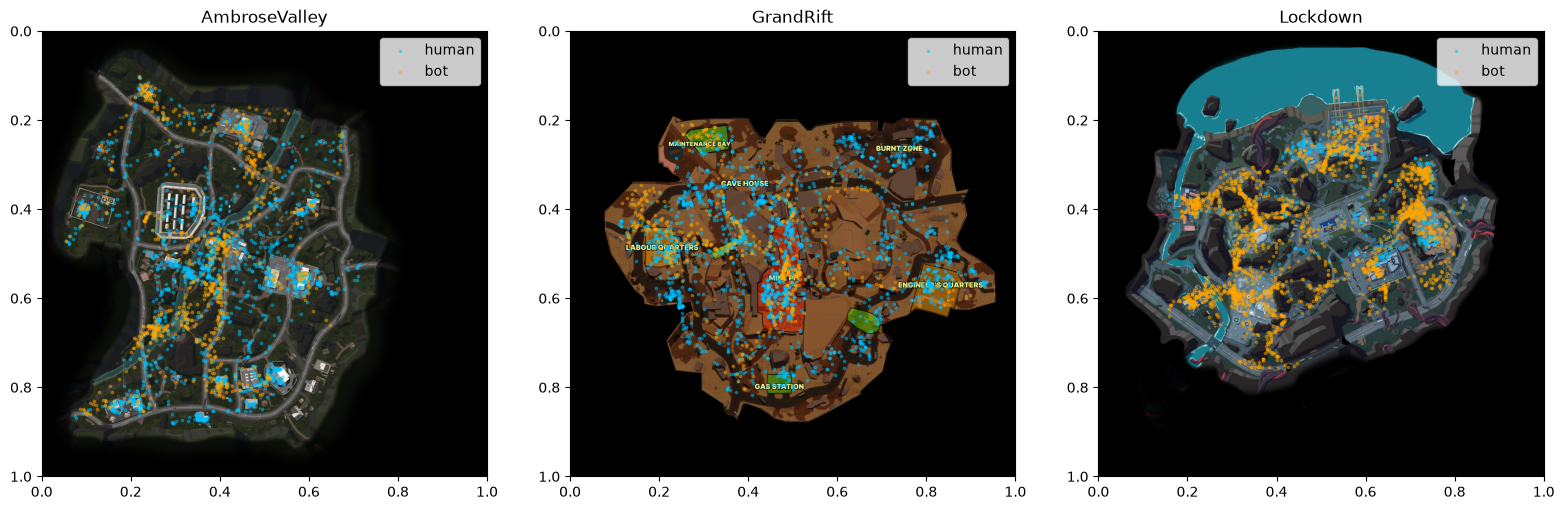

In [46]:
figure, axes = plt.subplots(1, 3, figsize=(16, 5))

for axis, map_name in zip(axes, minimap_files):
    with Image.open(minimap_files[map_name]) as minimap:
        minimap.thumbnail((1000, 1000))
        axis.imshow(minimap, extent=(0, 1, 1, 0))

    sample_events = map_events.filter(
        (F.col("map_id") == map_name) & F.col("inside_minimap"),
    )
    sample_events = sample_events.orderBy("source_file", "timestamp_value", "event")
    sample_points = sample_events.select(
        "u", "image_y_fraction", "actor_type",
    ).limit(2500).toPandas()

    for actor_type, color in [("human", "deepskyblue"), ("bot", "orange")]:
        actor_points = sample_points[sample_points["actor_type"] == actor_type]
        axis.scatter(
            actor_points["u"], actor_points["image_y_fraction"],
            s=3, alpha=0.4, color=color, label=actor_type,
        )

    axis.set_title(map_name)
    axis.set_xlim(0, 1)
    axis.set_ylim(1, 0)
    axis.legend()

plt.tight_layout()
print("\nMinimap alignment charts using up to 2,500 recorded events per map:")
plt.show()

## 13. What should a traffic heatmap count?

Count movement samples and distinct recorded journeys separately. A bot ID
reused in two matches is two journeys. A sample count is not time spent.
Empty cells may include unplayable terrain; they do not prove ignored areas.
The 32 by 32 grid is an exploratory setting, not a database partition scheme.

In [47]:
grid_size = 32
traffic_events = map_events.filter(
    F.col("inside_minimap") & F.col("event").isin("Position", "BotPosition"),
)

# A coordinate exactly on the upper boundary belongs to the final grid cell.
traffic_events = traffic_events.withColumn(
    "cell_x", F.least(F.lit(grid_size - 1), F.floor(F.col("u") * grid_size)).cast("int"),
)
traffic_events = traffic_events.withColumn(
    "cell_y",
    F.least(F.lit(grid_size - 1), F.floor(F.col("image_y_fraction") * grid_size)).cast("int"),
)
traffic_by_cell = traffic_events.groupBy("map_id", "actor_type", "cell_x", "cell_y").agg(
    F.count("*").alias("movement_samples"),
    F.countDistinct("user_id").alias("raw_actor_ids"),
    F.countDistinct(F.struct("match_id", "user_id")).alias("recorded_journeys"),
    F.countDistinct("match_id").alias("matches"),
)
print("\nTen busiest traffic cells by movement-sample count, split by actor type:")
traffic_by_cell.orderBy(F.desc("movement_samples")).show(10)
print("\nNumber of occupied 32-by-32 traffic grid cells for each map and actor type:")
traffic_by_cell.groupBy("map_id", "actor_type").count().orderBy("map_id", "actor_type").show()


Ten busiest traffic cells by movement-sample count, split by actor type:


+-------------+----------+------+------+----------------+-------------+-----------------+-------+
|       map_id|actor_type|cell_x|cell_y|movement_samples|raw_actor_ids|recorded_journeys|matches|
+-------------+----------+------+------+----------------+-------------+-----------------+-------+
|AmbroseValley|     human|    11|    27|             693|           63|               96|     95|
|AmbroseValley|     human|    18|    17|             674|           64|               94|     94|
|AmbroseValley|     human|     9|    16|             617|           70|               99|     99|
|AmbroseValley|     human|    12|    25|             617|           61|               94|     94|
|AmbroseValley|     human|    16|    24|             617|           49|               72|     72|
|AmbroseValley|     human|    16|    17|             608|           68|              109|    109|
|AmbroseValley|     human|    14|     6|             606|           36|               61|     61|
|AmbroseValley|     

+-------------+----------+-----+
|       map_id|actor_type|count|
+-------------+----------+-----+
|AmbroseValley|       bot|  402|
|AmbroseValley|     human|  438|
|    GrandRift|       bot|  290|
|    GrandRift|     human|  355|
|     Lockdown|       bot|  292|
|     Lockdown|     human|  321|
+-------------+----------+-----+




Traffic heatmaps for all three maps, using log-scaled movement-sample counts:


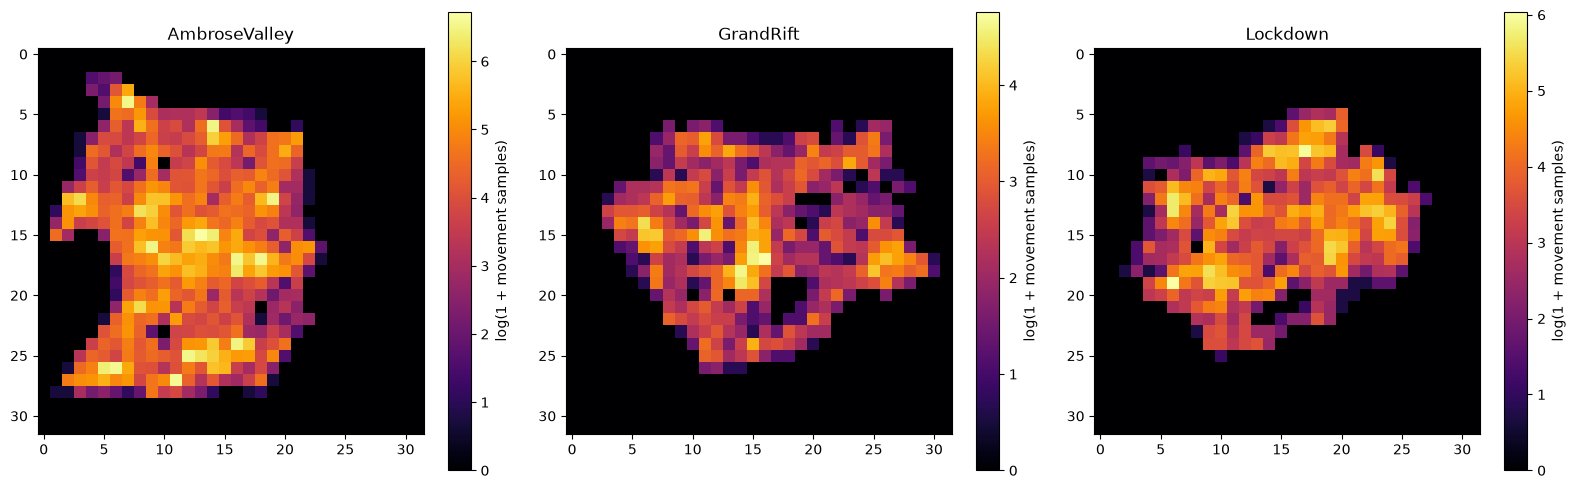

In [48]:
# Collect at most 3 maps * 32 * 32 aggregate cells, not every event.
heatmap_totals = traffic_by_cell.groupBy("map_id", "cell_x", "cell_y").agg(
    F.sum("movement_samples").alias("movement_samples"),
)
heatmap_data = heatmap_totals.toPandas()
figure, axes = plt.subplots(1, 3, figsize=(16, 5))

for axis, map_name in zip(axes, minimap_files):
    map_cells = heatmap_data[heatmap_data["map_id"] == map_name]
    cell_counts = np.zeros((grid_size, grid_size))
    for cell in map_cells.itertuples():
        cell_counts[cell.cell_y, cell.cell_x] = cell.movement_samples

    # Log scaling keeps busy cells from hiding the rest of the distribution.
    image = axis.imshow(np.log1p(cell_counts), cmap="inferno", origin="upper")
    axis.set_title(map_name)
    figure.colorbar(image, ax=axis, label="log(1 + movement samples)")

plt.tight_layout()
print("\nTraffic heatmaps for all three maps, using log-scaled movement-sample counts:")
plt.show()

## 14. Inspect one recorded match

Change `selected_match_id` below to inspect another match, then rerun this
section. The default is the match with the most recorded actors.
This is a view of available recordings, not a complete lobby reconstruction.

In [49]:
busiest_match = match_summary.orderBy(F.desc("recorded_actors"), "match_id").first()
selected_match_id = busiest_match["match_id"]

selected_summary = match_summary.filter(F.col("match_id") == selected_match_id)
print("\nRecorded coverage and timing summary for the selected match:")
selected_summary.show(truncate=False)
selected_summary_row = selected_summary.first()
if selected_summary_row is None:
    raise ValueError("The selected match ID was not found.")
selected_map = selected_summary_row["map_id"]

selected_events = map_events.filter(F.col("match_id") == selected_match_id)
if selected_events.count() > 20000:
    raise ValueError("This plot is limited to matches with at most 20,000 recorded events.")

# This is the only detailed event collection: one bounded, selected match.
match_plot_data = selected_events.select(
    "user_id", "actor_type", "event", "timestamp_value",
    "u", "image_y_fraction", "inside_minimap",
).orderBy("user_id", "timestamp_value", "event").toPandas()


Recorded coverage and timing summary for the selected match:


+---------------------------------------------+-------------+---------+----------------+---------------+---------------+-------------+----------+---------------+--------------+-------------+
|match_id                                     |map_id       |map_count|collection_dates|recorded_actors|recorded_humans|recorded_bots|event_rows|first_timestamp|last_timestamp|recorded_span|
+---------------------------------------------+-------------+---------+----------------+---------------+---------------+-------------+----------+---------------+--------------+-------------+
|fbbc5d02-dd79-42fb-bba5-d768023891c8.nakama-0|AmbroseValley|1        |1               |16             |1              |15           |1015      |1770927267     |1770927790    |523          |
+---------------------------------------------+-------------+---------+----------------+---------------+---------------+-------------+----------+---------------+--------------+-------------+




Selected-match journey map: solid human paths, dashed bot paths, and raw event markers:


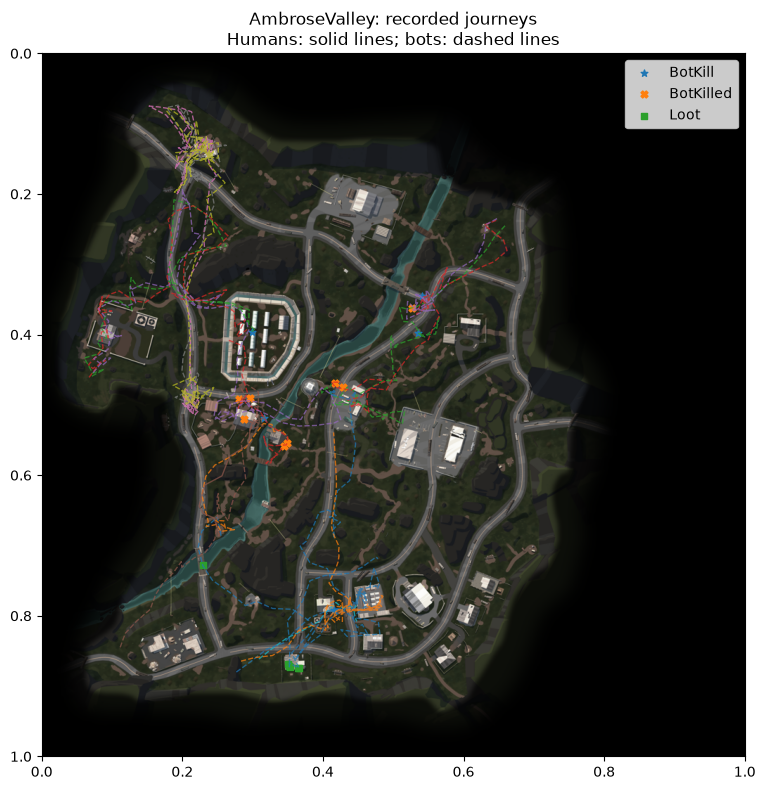

In [50]:
figure, axis = plt.subplots(figsize=(8, 8))
with Image.open(minimap_files[selected_map]) as minimap:
    minimap.thumbnail((1000, 1000))
    axis.imshow(minimap, extent=(0, 1, 1, 0))

for user_id, player_events in match_plot_data.groupby("user_id"):
    player_positions = player_events[
        player_events["event"].isin(["Position", "BotPosition"])
        & player_events["inside_minimap"]
    ]
    line_x = []
    line_y = []
    previous_time = None

    for position in player_positions.itertuples():
        # Break the line at a recording gap rather than inventing a route.
        if previous_time is not None and position.timestamp_value - previous_time > 15:
            line_x.append(np.nan)
            line_y.append(np.nan)
        line_x.append(position.u)
        line_y.append(position.image_y_fraction)
        previous_time = position.timestamp_value

    actor_type = player_events.iloc[0]["actor_type"]
    line_style = "--" if actor_type == "bot" else "-"
    axis.plot(line_x, line_y, linestyle=line_style, linewidth=1, alpha=0.7)

markers = {
    "Kill": "*",
    "BotKill": "*",
    "Killed": "X",
    "BotKilled": "X",
    "KilledByStorm": "P",
    "Loot": "s",
}
for event_name, marker in markers.items():
    event_points = match_plot_data[
        (match_plot_data["event"] == event_name) & match_plot_data["inside_minimap"]
    ]
    if not event_points.empty:
        axis.scatter(
            event_points["u"], event_points["image_y_fraction"],
            marker=marker, s=25, label=event_name,
        )

axis.set_title(f"{selected_map}: recorded journeys\nHumans: solid lines; bots: dashed lines")
axis.set_xlim(0, 1)
axis.set_ylim(1, 0)
if axis.get_legend_handles_labels()[0]:
    axis.legend()
plt.tight_layout()
print("\nSelected-match journey map: solid human paths, dashed bot paths, and raw event markers:")
plt.show()


Selected-match timeline showing when each participant has recorded events:


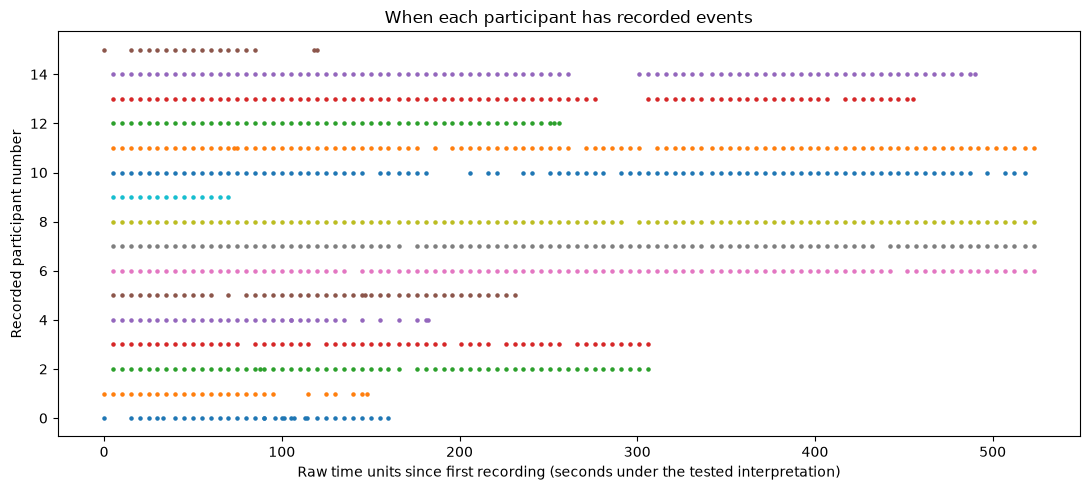

In [51]:
recording_start = match_plot_data["timestamp_value"].min()
figure, axis = plt.subplots(figsize=(11, 5))

for player_number, (user_id, player_events) in enumerate(match_plot_data.groupby("user_id")):
    elapsed_time = player_events["timestamp_value"] - recording_start
    axis.scatter(elapsed_time, [player_number] * len(player_events), s=5)

axis.set_title("When each participant has recorded events")
axis.set_xlabel("Raw time units since first recording (seconds under the tested interpretation)")
axis.set_ylabel("Recorded participant number")
plt.tight_layout()
print("\nSelected-match timeline showing when each participant has recorded events:")
plt.show()

## 15. What will the application query?

Two common reads are an overview filtered by map/day, and the ordered events
for one match. Keep these concrete queries in mind when choosing storage and
indexes. Spark's cached query plan is not a benchmark of a future database.

In [52]:
overview_events = events.filter(
    (F.col("map_id") == "AmbroseValley")
    & F.col("collection_date").between("2026-02-10", "2026-02-14"),
)
overview_counts = overview_events.groupBy("event", "actor_type").count()
print("\nEvent counts for Ambrose Valley collected from February 10 through February 14:")
overview_counts.orderBy("event", "actor_type").show()

replay_events = match_timeline.filter(F.col("match_id") == selected_match_id)
replay_events = replay_events.select(
    "user_id", "actor_type", "event", "x", "y", "z",
    "timestamp_value", "elapsed_raw_units", "source_file",
)
replay_events = replay_events.orderBy("timestamp_value", "user_id", "event")
print("\nFirst ten chronological events returned by the selected-match replay query:")
replay_events.show(10, truncate=False)
print("\nSpark physical execution plan for the selected-match replay query:")
replay_events.explain()


Event counts for Ambrose Valley collected from February 10 through February 14:


+-------------+----------+-----+
|        event|actor_type|count|
+-------------+----------+-----+
|      BotKill|       bot|  133|
|      BotKill|     human| 1664|
|    BotKilled|       bot|  189|
|    BotKilled|     human|  297|
|  BotPosition|       bot|12565|
|         Kill|     human|    2|
|       Killed|     human|    2|
|KilledByStorm|     human|   17|
|         Loot|       bot|  111|
|         Loot|     human| 9844|
|     Position|       bot|  587|
|     Position|     human|35602|
+-------------+----------+-----+




First ten chronological events returned by the selected-match replay query:
+------------------------------------+----------+-----------+----------+----------+----------+---------------+-----------------+----------------------------------------------------------------------------------------------+
|user_id                             |actor_type|event      |x         |y         |z         |timestamp_value|elapsed_raw_units|source_file                                                                                   |
+------------------------------------+----------+-----------+----------+----------+----------+---------------+-----------------+----------------------------------------------------------------------------------------------+
|1429                                |bot       |Position   |-140.40155|101.335556|-190.52092|1770927267     |0                |February_12/1429_fbbc5d02-dd79-42fb-bba5-d768023891c8.nakama-0                                |
|1432                      

## 16. What does this imply for database design?

These are proposals supported by this dataset, not a production migration.

| Table | What belongs here | Reason |
|---|---|---|
| Maps | Map ID, world origin/scale, asset path, actual image dimensions, configuration version | Coordinates and image sizes differ by map. |
| Source files | File ID, dataset version, relative path, content hash, collection date, import status | A file is provenance. Preserve its identity when imports are retried. |
| Matches | Exact match ID including suffix, map ID, first/last observed time | Every observed match belongs to one map; observed bounds are not verified match duration. |
| Recorded participants | Participant ID, match ID, source user ID, human/bot classification | One journey is one actor within one match. Numeric bot IDs may be reused. |
| Events | Event ID, participant ID, source file ID, original row number, raw event label, raw timestamp, X/Y/Z | No supplied natural event key is unique. Preserve original values and event multiplicity. |
| Journey/file links | Participant ID, source file ID | One recorded journey can span multiple source files and collection dates. |
| Derived summaries | Map coordinates, interpreted time, heatmap cells | These should be rebuildable using documented transformation versions. |

**Keys:** use a surrogate event ID plus a unique source-file/row identity within
a dataset version. Do not use Spark partition numbering as a stable row identity.
A repeated payload is not enough evidence to remove an event.

**Dates:** keep collection date on the source file. Do not force a single
collection date onto a match. Keep raw time and its declared unit separately
from any inferred event timestamp.

**Query access:** evaluate participant/time and match/time indexes for replay,
and map/date access for overview queries. Depending on normalization, filters
may traverse related tables. Do not add every index without checking the plan.

**Storage:** the Parquet data is about 8.4 MB in many small files. Compacted
Parquet or generated per-match assets may be enough for the initial tool.
A query API or concurrent writers could justify a database server. Spark is
useful for this analysis; these data volumes do not require a production cluster.

**Unresolved:** timestamp unit/timezone, bot combat semantics, global bot identity,
sparse match coverage, death-state behavior, and whether repeated loot payloads
are independent pickups. There are no explicit killer/victim links, extraction
outcomes, storm boundaries, or item identities in the supplied schema.

## 17. Check that the rewrite preserved the previous audit results

These checks compare with the existing audit of this exact supplied dataset.
They are regression checks for the analysis, not rules for future production data.

In [53]:
assert total_event_rows == 89104
assert len(parquet_files) == 1243
assert player_journeys.count() == 1242
assert match_summary.count() == 796
assert match_summary.filter(F.col("recorded_actors") == 1).count() == 743
assert repeated_payloads.count() == 1360

repeated_rows = repeated_payloads.agg(
    F.sum(F.col("copies") - 1).alias("rows_beyond_first"),
).first()
assert repeated_rows["rows_beyond_first"] == 1505
assert outside_map.count() == 0
assert filename_mismatches.count() == 0
assert unexpected_files.count() == 0

print("The key counts agree with the previous full-data audit.")
print("Spark remains available for your own queries below.")

The key counts agree with the previous full-data audit.
Spark remains available for your own queries below.


## Exact-timestamp candidate pairs without a distance requirement

This is the query requested after the proximity experiment. It applies these rules:

1. The two different user IDs belong to the same match; their distance does not matter.
2. One has `Kill` or `BotKill`, and the other has `Killed` or `BotKilled`, at exactly the same stored timestamp value.
3. The second ID has no `Position` or `BotPosition` record **after** that timestamp anywhere later in the same match. A position at the death timestamp is allowed.

There is no time tolerance, distance check, requirement that the killer continues moving, or requirement that the match recording continues. Storm deaths are not treated as combat deaths. Equality uses the original stored integer, so it does not depend on the unresolved seconds/milliseconds interpretation.

`DISTINCT` lists matching ID/time/label combinations once; it does not delete source rows or establish a unique gameplay-kill count. If several IDs satisfy these rules at the same time, all matching pairs are retained. These are inferred candidates rather than source-provided killer/victim links.

In [54]:
events.createOrReplaceTempView("player_events")

same_timestamp_query = """
-- Spark SQL. First register the notebook's decoded events DataFrame:
-- events.createOrReplaceTempView("player_events")
-- timestamp_value is the original integer recovered from the stored timestamp.
-- DISTINCT lists each matching ID/time/label combination once.

SELECT DISTINCT
    killer.match_id,
    killer.map_id,
    killer.timestamp_value AS event_timestamp,
    killer.user_id AS possible_killer_id,
    killer.actor_type AS possible_killer_type,
    killer.event AS kill_event,
    victim.user_id AS possible_victim_id,
    victim.actor_type AS possible_victim_type,
    victim.event AS death_event
FROM player_events AS killer
JOIN player_events AS victim
    ON victim.match_id = killer.match_id
    AND victim.timestamp_value = killer.timestamp_value
    AND victim.user_id <> killer.user_id
WHERE killer.event IN ('Kill', 'BotKill')
    AND victim.event IN ('Killed', 'BotKilled')
    AND NOT EXISTS (
        SELECT 1
        FROM player_events AS later_position
        WHERE later_position.match_id = victim.match_id
            AND later_position.user_id = victim.user_id
            AND later_position.event IN ('Position', 'BotPosition')
            AND later_position.timestamp_value > victim.timestamp_value
    )
ORDER BY
    match_id,
    event_timestamp,
    possible_killer_id,
    possible_victim_id,
    kill_event,
    death_event;
"""

print("SQL query for matching kill/death timestamps with no later victim positions and no distance filter:")
print(same_timestamp_query)
same_timestamp_pairs = spark.sql(same_timestamp_query).cache()

SQL query for matching kill/death timestamps with no later victim positions and no distance filter:

-- Spark SQL. First register the notebook's decoded events DataFrame:
-- events.createOrReplaceTempView("player_events")
-- timestamp_value is the original integer recovered from the stored timestamp.
-- DISTINCT lists each matching ID/time/label combination once.

SELECT DISTINCT
    killer.match_id,
    killer.map_id,
    killer.timestamp_value AS event_timestamp,
    killer.user_id AS possible_killer_id,
    killer.actor_type AS possible_killer_type,
    killer.event AS kill_event,
    victim.user_id AS possible_victim_id,
    victim.actor_type AS possible_victim_type,
    victim.event AS death_event
FROM player_events AS killer
JOIN player_events AS victim
    ON victim.match_id = killer.match_id
    AND victim.timestamp_value = killer.timestamp_value
    AND victim.user_id <> killer.user_id
WHERE killer.event IN ('Kill', 'BotKill')
    AND victim.event IN ('Killed', 'BotKilled')
  

In [55]:
print("Summary of candidate pairs satisfying the exact-timestamp and movement-ending rules:")
same_timestamp_pairs.agg(
    F.count("*").alias("candidate_pairs"),
    F.countDistinct("match_id").alias("matches"),
    F.countDistinct(F.struct(
        "match_id", "event_timestamp", "possible_killer_id", "kill_event"
    )).alias("kill_actor_time_label_groups"),
    F.countDistinct(F.struct(
        "match_id", "event_timestamp", "possible_victim_id", "death_event"
    )).alias("victim_time_label_groups"),
).show()

print("Candidate pairs split by recorded killer and victim ID types:")
same_timestamp_pairs.groupBy(
    "possible_killer_type", "possible_victim_type"
).count().orderBy("possible_killer_type", "possible_victim_type").show()

Summary of candidate pairs satisfying the exact-timestamp and movement-ending rules:


+---------------+-------+----------------------------+------------------------+
|candidate_pairs|matches|kill_actor_time_label_groups|victim_time_label_groups|
+---------------+-------+----------------------------+------------------------+
|             80|     34|                          74|                      78|
+---------------+-------+----------------------------+------------------------+

Candidate pairs split by recorded killer and victim ID types:
+--------------------+--------------------+-----+
|possible_killer_type|possible_victim_type|count|
+--------------------+--------------------+-----+
|                 bot|                 bot|   49|
|                 bot|               human|    3|
|               human|                 bot|   28|
+--------------------+--------------------+-----+



In [56]:
# Keep every matching pair; report how many counterpart IDs are possible.
victim_candidates_per_kill = same_timestamp_pairs.groupBy(
    "match_id", "event_timestamp", "possible_killer_id"
).agg(F.countDistinct("possible_victim_id").alias("possible_victims_at_timestamp"))

killer_candidates_per_victim = same_timestamp_pairs.groupBy(
    "match_id", "event_timestamp", "possible_victim_id"
).agg(F.countDistinct("possible_killer_id").alias("possible_killers_at_timestamp"))

same_timestamp_pair_details = same_timestamp_pairs.join(
    victim_candidates_per_kill,
    on=["match_id", "event_timestamp", "possible_killer_id"], how="left",
)
same_timestamp_pair_details = same_timestamp_pair_details.join(
    killer_candidates_per_victim,
    on=["match_id", "event_timestamp", "possible_victim_id"], how="left",
)

victim_last_positions = movement_events.groupBy("match_id", "user_id").agg(
    F.max("timestamp_value").alias("victim_last_position_time")
).withColumnRenamed("user_id", "possible_victim_id")
same_timestamp_pair_details = same_timestamp_pair_details.join(
    victim_last_positions, on=["match_id", "possible_victim_id"], how="left"
)
same_timestamp_pair_details = same_timestamp_pair_details.withColumn(
    "victim_last_position_offset",
    F.col("victim_last_position_time") - F.col("event_timestamp"),
)

print("How many possible killer IDs match each victim and timestamp:")
killer_candidates_per_victim.groupBy("possible_killers_at_timestamp").count().orderBy(
    "possible_killers_at_timestamp"
).show()

print("How many possible victim IDs match each killer and timestamp:")
victim_candidates_per_kill.groupBy("possible_victims_at_timestamp").count().orderBy(
    "possible_victims_at_timestamp"
).show()

print("Number of pairs that have exactly one counterpart ID in each direction:")
same_timestamp_pair_details.filter(
    (F.col("possible_killers_at_timestamp") == 1)
    & (F.col("possible_victims_at_timestamp") == 1)
).agg(F.count("*").alias("one_to_one_candidate_pairs")).show()

How many possible killer IDs match each victim and timestamp:


+-----------------------------+-----+
|possible_killers_at_timestamp|count|
+-----------------------------+-----+
|                            1|   76|
|                            2|    2|
+-----------------------------+-----+

How many possible victim IDs match each killer and timestamp:
+-----------------------------+-----+
|possible_victims_at_timestamp|count|
+-----------------------------+-----+
|                            1|   68|
|                            2|    6|
+-----------------------------+-----+

Number of pairs that have exactly one counterpart ID in each direction:


+--------------------------+
|one_to_one_candidate_pairs|
+--------------------------+
|                        68|
+--------------------------+



In [57]:
# List all results, not just the default first twenty rows.
ordered_timestamp_pairs = same_timestamp_pair_details.select(
    "match_id", "map_id", "event_timestamp",
    "possible_killer_id", "possible_killer_type", "kill_event",
    "possible_victim_id", "possible_victim_type", "death_event",
    "victim_last_position_time", "victim_last_position_offset",
    "possible_killers_at_timestamp", "possible_victims_at_timestamp",
).orderBy(
    "match_id", "event_timestamp", "possible_killer_id", "possible_victim_id"
)
total_timestamp_pairs = ordered_timestamp_pairs.count()
print(f"All {total_timestamp_pairs} candidate pairs, including movement endpoints and counterpart counts:")
ordered_timestamp_pairs.show(max(total_timestamp_pairs, 1), truncate=False)

# Export this small derived list for inspection outside the notebook.
analysis_folder = project_folder / "rough work" / "analysis"
analysis_folder.mkdir(parents=True, exist_ok=True)
result_path = analysis_folder / "same_timestamp_kill_candidates.csv"
ordered_timestamp_pairs.toPandas().to_csv(result_path, index=False)
print("Full candidate list saved to:", result_path)

# The SQL must exclude every participant with later position records.
assert same_timestamp_pair_details.filter(
    F.col("victim_last_position_time") > F.col("event_timestamp")
).count() == 0
print("Verified: none of the listed victim candidates has a later position record.")

All 80 candidate pairs, including movement endpoints and counterpart counts:


+---------------------------------------------+-------------+---------------+------------------------------------+--------------------+----------+------------------------------------+--------------------+-----------+-------------------------+---------------------------+-----------------------------+-----------------------------+
|match_id                                     |map_id       |event_timestamp|possible_killer_id                  |possible_killer_type|kill_event|possible_victim_id                  |possible_victim_type|death_event|victim_last_position_time|victim_last_position_offset|possible_killers_at_timestamp|possible_victims_at_timestamp|
+---------------------------------------------+-------------+---------------+------------------------------------+--------------------+----------+------------------------------------+--------------------+-----------+-------------------------+---------------------------+-----------------------------+-----------------------------+
|053027

Full candidate list saved to: /Users/mskbaruah/Documents/ChatGPT/LILA games/docs/analysis/same_timestamp_kill_candidates.csv


Verified: none of the listed victim candidates has a later position record.


### Results using only the requested exact-timestamp rules

The query returns **80 distinct candidate ID/time/label pairs across 34 matches**, covering 74 killer/time/label groups and 78 victim/time/label groups. The raw labels for all returned pairs are `BotKill` and `BotKilled`.

| Recorded ID types | Candidate pairs |
|---|---:|
| Human → bot | 28 |
| Bot → human | 3 |
| Bot → bot | 49 |

There are **68 pairs with exactly one matching counterpart ID in both directions**. The remaining 12 pairs have multiple possible counterparts at the same timestamp. In particular, two victim/time groups each match two different potential killer IDs. All alternatives remain in the list; this query does not select a winner or establish unique gameplay kills.

Every listed victim has a last recorded position at or before the kill/death timestamp. A later position would exclude that pair. There are no distance, lookback, continuing-killer, or remaining-match-duration filters.

All results and movement endpoints are listed in the preceding output and exported to `rough work/analysis/same_timestamp_kill_candidates.csv`. The exact SQL is stored in `rough work/queries/same_timestamp_kill_candidates.sql` and displayed above. `possible_killers_at_timestamp` and `possible_victims_at_timestamp` in the CSV make simultaneous alternatives visible.

## Test whether every same-timestamp kill/death pair is followed by a movement ending

The previous query kept only pairs whose death-labelled actor had no later positions. It therefore cannot establish that all same-time pairs follow this pattern. This audit first keeps **every** distinct-ID same-match same-time kill/death label combination, and then measures the later positions of both actors.

We report two separate requirements:

- **Earlier victim rule:** the death-labelled ID has no later `Position` or `BotPosition` record.
- **New broader rule:** at least one of the two IDs has no later position record. Cases where only the kill-labelled ID stops do not establish that the death-labelled ID was the victim.

All actor types are included, and human-versus-human candidates are shown explicitly. No distance filter is used. A position at the event timestamp is allowed. We also group by match/timestamp so that several possible cross-pairings at a simultaneous encounter are not mistaken for independent confirmed incidents. Missing movement history is reported as unassessable.

For this audit, “stops” keeps the earlier operational definition of **no later position record**. The detailed examples show later coordinates and timing so that a final delayed sample is not silently interpreted as continued live gameplay. Even full agreement would support a rule in this supplied dataset rather than prove an explicit killer/victim identity.

In [58]:
events.createOrReplaceTempView("player_events")

simultaneous_audit_query = """
-- Spark SQL against the notebook's decoded player_events view.
-- Keep every same-time pair. Movement endings are results, not filters.
WITH movement_endings AS (
    SELECT
        match_id,
        user_id,
        MAX(timestamp_value) AS last_position_time
    FROM player_events
    WHERE event IN ('Position', 'BotPosition')
    GROUP BY match_id, user_id
),
simultaneous_pairs AS (
    SELECT DISTINCT
        killer.match_id,
        killer.map_id,
        killer.timestamp_value AS event_timestamp,
        killer.user_id AS possible_killer_id,
        killer.actor_type AS possible_killer_type,
        killer.event AS kill_event,
        victim.user_id AS possible_victim_id,
        victim.actor_type AS possible_victim_type,
        victim.event AS death_event
    FROM player_events AS killer
    JOIN player_events AS victim
        ON victim.match_id = killer.match_id
        AND victim.timestamp_value = killer.timestamp_value
        AND victim.user_id <> killer.user_id
    WHERE killer.event IN ('Kill', 'BotKill')
        AND victim.event IN ('Killed', 'BotKilled')
)
SELECT
    pair.*,
    killer_positions.last_position_time AS killer_last_position_time,
    victim_positions.last_position_time AS victim_last_position_time,
    killer_positions.last_position_time - pair.event_timestamp AS killer_last_position_offset,
    victim_positions.last_position_time - pair.event_timestamp AS victim_last_position_offset,
    killer_positions.last_position_time > pair.event_timestamp AS killer_has_later_positions,
    victim_positions.last_position_time > pair.event_timestamp AS victim_has_later_positions,
    CASE
        WHEN killer_positions.last_position_time IS NULL
            OR victim_positions.last_position_time IS NULL
            THEN 'missing_position_history'
        WHEN victim_positions.last_position_time <= pair.event_timestamp
            THEN 'victim_has_no_later_positions'
        WHEN killer_positions.last_position_time <= pair.event_timestamp
            THEN 'only_killer_has_no_later_positions'
        ELSE 'both_have_later_positions'
    END AS movement_result
FROM simultaneous_pairs AS pair
LEFT JOIN movement_endings AS killer_positions
    ON killer_positions.match_id = pair.match_id
    AND killer_positions.user_id = pair.possible_killer_id
LEFT JOIN movement_endings AS victim_positions
    ON victim_positions.match_id = pair.match_id
    AND victim_positions.user_id = pair.possible_victim_id
ORDER BY
    pair.match_id,
    pair.event_timestamp,
    pair.possible_killer_id,
    pair.possible_victim_id;
"""
print("Audit query: retain all same-time kill/death pairs and measure both actors' movement endings:")
print(simultaneous_audit_query)
simultaneous_pair_audit = spark.sql(simultaneous_audit_query).cache()
simultaneous_pair_audit.createOrReplaceTempView("simultaneous_pair_audit")

print("All same-timestamp pairs, split by movement result:")
simultaneous_pair_audit.groupBy("movement_result").agg(
    F.count("*").alias("candidate_pairs"),
    F.countDistinct("match_id").alias("matches"),
    F.countDistinct(F.struct("match_id", "event_timestamp")).alias("match_timestamp_groups"),
).orderBy("movement_result").show(truncate=False)

print("Results for every actor-type combination, including human versus human:")
simultaneous_pair_audit.groupBy(
    "possible_killer_type", "possible_victim_type", "movement_result"
).count().orderBy(
    "possible_killer_type", "possible_victim_type", "movement_result"
).show(30, truncate=False)

Audit query: retain all same-time kill/death pairs and measure both actors' movement endings:

-- Spark SQL against the notebook's decoded player_events view.
-- Keep every same-time pair. Movement endings are results, not filters.
WITH movement_endings AS (
    SELECT
        match_id,
        user_id,
        MAX(timestamp_value) AS last_position_time
    FROM player_events
    WHERE event IN ('Position', 'BotPosition')
    GROUP BY match_id, user_id
),
simultaneous_pairs AS (
    SELECT DISTINCT
        killer.match_id,
        killer.map_id,
        killer.timestamp_value AS event_timestamp,
        killer.user_id AS possible_killer_id,
        killer.actor_type AS possible_killer_type,
        killer.event AS kill_event,
        victim.user_id AS possible_victim_id,
        victim.actor_type AS possible_victim_type,
        victim.event AS death_event
    FROM player_events AS killer
    JOIN player_events AS victim
        ON victim.match_id = killer.match_id
        AND victim.t

+-----------------------------+---------------+-------+----------------------+
|movement_result              |candidate_pairs|matches|match_timestamp_groups|
+-----------------------------+---------------+-------+----------------------+
|both_have_later_positions    |2              |2      |2                     |
|victim_has_no_later_positions|80             |34     |73                    |
+-----------------------------+---------------+-------+----------------------+

Results for every actor-type combination, including human versus human:
+--------------------+--------------------+-----------------------------+-----+
|possible_killer_type|possible_victim_type|movement_result              |count|
+--------------------+--------------------+-----------------------------+-----+
|bot                 |bot                 |victim_has_no_later_positions|49   |
|bot                 |human               |both_have_later_positions    |2    |
|bot                 |human               |victim_has

In [59]:
human_vs_human_pairs = simultaneous_pair_audit.filter(
    (F.col("possible_killer_type") == "human")
    & (F.col("possible_victim_type") == "human")
)
print("Human-versus-human candidate pairs with two different IDs:")
print("Number of matching pairs:", human_vs_human_pairs.count())
human_vs_human_pairs.show(20, truncate=False)

print("All supplied Kill and Killed rows, with movement continuing beyond their timestamps:")
human_combat_labels = events.filter(F.col("event").isin("Kill", "Killed"))
human_combat_labels = human_combat_labels.join(
    participant_movement_bounds.select("match_id", "user_id", "last_position_time"),
    on=["match_id", "user_id"], how="left",
)
human_combat_labels.select(
    "match_id", "user_id", "event", "timestamp_value",
    (F.col("last_position_time") - F.col("timestamp_value")).alias("last_position_offset"),
).orderBy("match_id", "timestamp_value", "event").show(truncate=False)

print("Same-ID Kill/Killed label coincidences; these are not two-player pairings:")
same_id_human_labels = human_combat_labels.groupBy(
    "match_id", "user_id", "timestamp_value"
).agg(F.collect_set("event").alias("labels"))
same_id_human_labels.filter(
    F.array_contains("labels", "Kill") & F.array_contains("labels", "Killed")
).show(truncate=False)

Human-versus-human candidate pairs with two different IDs:
Number of matching pairs: 0


+--------+------+---------------+------------------+--------------------+----------+------------------+--------------------+-----------+-------------------------+-------------------------+---------------------------+---------------------------+--------------------------+--------------------------+---------------+
|match_id|map_id|event_timestamp|possible_killer_id|possible_killer_type|kill_event|possible_victim_id|possible_victim_type|death_event|killer_last_position_time|victim_last_position_time|killer_last_position_offset|victim_last_position_offset|killer_has_later_positions|victim_has_later_positions|movement_result|
+--------+------+---------------+------------------+--------------------+----------+------------------+--------------------+-----------+-------------------------+-------------------------+---------------------------+---------------------------+--------------------------+--------------------------+---------------+
+--------+------+---------------+------------------+---

+---------------------------------------------+------------------------------------+------+---------------+--------------------+
|match_id                                     |user_id                             |event |timestamp_value|last_position_offset|
+---------------------------------------------+------------------------------------+------+---------------+--------------------+
|042774ea-d909-40a4-9d02-ac3be13529ec.nakama-0|b2365f20-2a38-4094-b8bb-da6ee9996b39|Kill  |1770727293     |2                   |
|042774ea-d909-40a4-9d02-ac3be13529ec.nakama-0|b2365f20-2a38-4094-b8bb-da6ee9996b39|Killed|1770727293     |2                   |
|711c9a67-dd8c-4070-90e4-c606b89c007d.nakama-0|7778267b-cdff-45c5-9616-4f3b07af9758|Kill  |1770716419     |1                   |
|711c9a67-dd8c-4070-90e4-c606b89c007d.nakama-0|7778267b-cdff-45c5-9616-4f3b07af9758|Killed|1770716419     |1                   |
|c4a250c9-6c7c-417d-ad23-3a2683b7dd96.nakama-0|00f02e70-ec72-4411-9078-0d98939caa62|Kill  |177079

In [60]:
# Examine whole match/timestamp groups, not only all possible cross-pairs.
simultaneous_group_results = simultaneous_pair_audit.groupBy(
    "match_id", "event_timestamp"
).agg(
    F.count("*").alias("possible_pairs"),
    F.countDistinct("possible_killer_id").alias("possible_killers"),
    F.countDistinct("possible_victim_id").alias("possible_victims"),
    F.sum(F.when(
        F.col("movement_result") == "victim_has_no_later_positions", 1
    ).otherwise(0)).alias("pairs_with_ending_victim"),
    F.sum(F.when(
        F.col("movement_result").isin(
            "victim_has_no_later_positions", "only_killer_has_no_later_positions"
        ), 1
    ).otherwise(0)).alias("pairs_with_either_actor_ending"),
    F.sum(F.when(
        F.col("movement_result") == "missing_position_history", 1
    ).otherwise(0)).alias("unassessable_pairs"),
)

print("Group-level test: does every same-time encounter have at least one candidate actor ending movement?")
simultaneous_group_results.agg(
    F.count("*").alias("same_time_groups_with_distinct_ids"),
    F.sum(F.when(F.col("pairs_with_ending_victim") > 0, 1).otherwise(0)).alias("groups_with_ending_victim_candidate"),
    F.sum(F.when(F.col("pairs_with_either_actor_ending") > 0, 1).otherwise(0)).alias("groups_with_either_actor_ending"),
    F.sum(F.when(
        (F.col("pairs_with_either_actor_ending") == 0)
        & (F.col("unassessable_pairs") == 0), 1
    ).otherwise(0)).alias("groups_where_every_pair_keeps_positions"),
).show(truncate=False)

print("Clear counterexample groups with exactly one possible killer and victim, both continuing positions:")
clear_counterexample_groups = simultaneous_group_results.filter(
    (F.col("possible_killers") == 1)
    & (F.col("possible_victims") == 1)
    & (F.col("pairs_with_either_actor_ending") == 0)
    & (F.col("unassessable_pairs") == 0)
)
clear_counterexample_groups.show(30, truncate=False)

Group-level test: does every same-time encounter have at least one candidate actor ending movement?


+----------------------------------+-----------------------------------+-------------------------------+---------------------------------------+
|same_time_groups_with_distinct_ids|groups_with_ending_victim_candidate|groups_with_either_actor_ending|groups_where_every_pair_keeps_positions|
+----------------------------------+-----------------------------------+-------------------------------+---------------------------------------+
|75                                |73                                 |73                             |2                                      |
+----------------------------------+-----------------------------------+-------------------------------+---------------------------------------+

Clear counterexample groups with exactly one possible killer and victim, both continuing positions:


+---------------------------------------------+---------------+--------------+----------------+----------------+------------------------+------------------------------+------------------+
|match_id                                     |event_timestamp|possible_pairs|possible_killers|possible_victims|pairs_with_ending_victim|pairs_with_either_actor_ending|unassessable_pairs|
+---------------------------------------------+---------------+--------------+----------------+----------------+------------------------+------------------------------+------------------+
|fc797a67-e443-4f70-8813-5d2f30317e79.nakama-0|1770834920     |1             |1               |1               |0                       |0                             |0                 |
|413b9011-a43d-4957-a485-261668c9857b.nakama-0|1770706108     |1             |1               |1               |0                       |0                             |0                 |
+---------------------------------------------+-------------

In [61]:
print("Every pair where the death-labelled actor has later position records:")
victim_movement_exceptions = simultaneous_pair_audit.filter(
    F.col("victim_has_later_positions")
)
victim_movement_exceptions.show(max(victim_movement_exceptions.count(), 1), truncate=False)

print("Every pair where both actors have later position records:")
both_movement_exceptions = simultaneous_pair_audit.filter(
    F.col("movement_result") == "both_have_later_positions"
)
both_movement_exceptions.show(max(both_movement_exceptions.count(), 1), truncate=False)

print("Summary for the broad rule: every same-time pair should have at least one actor with no later positions:")
print("All distinct-ID same-timestamp pairs:", simultaneous_pair_audit.count())
print("Pairs where both actors continue recording positions:", both_movement_exceptions.count())
print("Groups with a clear single-pair counterexample:", clear_counterexample_groups.count())

# Prefer a single-pair example with the longest later victim recording.
exception_example = simultaneous_pair_audit.join(
    clear_counterexample_groups.select("match_id", "event_timestamp"),
    on=["match_id", "event_timestamp"], how="inner",
).orderBy(F.desc("victim_last_position_offset"), "match_id", "event_timestamp").first()

if exception_example is not None:
    exception_match = exception_example["match_id"]
    exception_time = exception_example["event_timestamp"]
    exception_killer = exception_example["possible_killer_id"]
    exception_victim = exception_example["possible_victim_id"]
    print("Counterexample match:", exception_match)
    print("Kill-labelled ID:", exception_killer)
    print("Death-labelled ID:", exception_victim)
    print("Kill-labelled actor's last position offset:", exception_example["killer_last_position_offset"])
    print("Death-labelled actor's last position offset:", exception_example["victim_last_position_offset"])
    print("Both actors' nearby event and position records, retaining coordinates for inspection:")
    events.filter(
        (F.col("match_id") == exception_match)
        & F.col("user_id").isin(exception_killer, exception_victim)
        & F.col("timestamp_value").between(exception_time - 5, exception_time + 30)
    ).select(
        "user_id", "event",
        (F.col("timestamp_value") - exception_time).alias("time_from_event"),
        "x", "y", "z",
    ).orderBy("time_from_event", "user_id", "event").show(80, truncate=False)
else:
    print("No distinct-ID single-pair group contradicts the broad movement-ending rule.")

Every pair where the death-labelled actor has later position records:
+---------------------------------------------+--------+---------------+------------------+--------------------+----------+------------------------------------+--------------------+-----------+-------------------------+-------------------------+---------------------------+---------------------------+--------------------------+--------------------------+-------------------------+
|match_id                                     |map_id  |event_timestamp|possible_killer_id|possible_killer_type|kill_event|possible_victim_id                  |possible_victim_type|death_event|killer_last_position_time|victim_last_position_time|killer_last_position_offset|victim_last_position_offset|killer_has_later_positions|victim_has_later_positions|movement_result          |
+---------------------------------------------+--------+---------------+------------------+--------------------+----------+------------------------------------+------

+---------------------------------------------+--------+---------------+------------------+--------------------+----------+------------------------------------+--------------------+-----------+-------------------------+-------------------------+---------------------------+---------------------------+--------------------------+--------------------------+-------------------------+
|match_id                                     |map_id  |event_timestamp|possible_killer_id|possible_killer_type|kill_event|possible_victim_id                  |possible_victim_type|death_event|killer_last_position_time|victim_last_position_time|killer_last_position_offset|victim_last_position_offset|killer_has_later_positions|victim_has_later_positions|movement_result          |
+---------------------------------------------+--------+---------------+------------------+--------------------+----------+------------------------------------+--------------------+-----------+-------------------------+-----------------

Groups with a clear single-pair counterexample: 2
Counterexample match: fc797a67-e443-4f70-8813-5d2f30317e79.nakama-0
Kill-labelled ID: 1435
Death-labelled ID: db454a35-d216-4379-b140-2931160c7d8a
Kill-labelled actor's last position offset: 166
Death-labelled actor's last position offset: 5
Both actors' nearby event and position records, retaining coordinates for inspection:


+------------------------------------+-----------+---------------+---------+---------+---------+
|user_id                             |event      |time_from_event|x        |y        |z        |
+------------------------------------+-----------+---------------+---------+---------+---------+
|1435                                |BotPosition|-5             |55.65924 |34.25    |227.97815|
|db454a35-d216-4379-b140-2931160c7d8a|Position   |-5             |31.598305|38.592247|219.38231|
|db454a35-d216-4379-b140-2931160c7d8a|Position   |-5             |31.598305|38.592247|219.38231|
|1435                                |BotKill    |0              |80.95557 |34.413338|231.05884|
|1435                                |BotPosition|0              |79.20178 |34.34671 |230.80011|
|db454a35-d216-4379-b140-2931160c7d8a|BotKilled  |0              |43.646393|38.854073|220.36707|
|db454a35-d216-4379-b140-2931160c7d8a|BotKilled  |0              |43.646393|38.854073|220.36707|
|db454a35-d216-4379-b140-29311

In [62]:
analysis_folder = project_folder / "rough work" / "analysis"
analysis_folder.mkdir(parents=True, exist_ok=True)

all_pairs_path = analysis_folder / "all_same_timestamp_kill_death_audit.csv"
exception_pairs_path = analysis_folder / "same_timestamp_movement_exceptions.csv"

simultaneous_pair_audit.orderBy(
    "match_id", "event_timestamp", "possible_killer_id", "possible_victim_id"
).toPandas().to_csv(all_pairs_path, index=False)
victim_movement_exceptions.orderBy(
    "match_id", "event_timestamp", "possible_killer_id", "possible_victim_id"
).toPandas().to_csv(exception_pairs_path, index=False)

print("Full unfiltered audit saved to:", all_pairs_path)
print("Pairs contradicting the no-later-victim-position rule saved to:", exception_pairs_path)
print("The original candidate query remains a selection rule; it does not establish a universal law.")

Full unfiltered audit saved to: /Users/mskbaruah/Documents/ChatGPT/LILA games/docs/analysis/all_same_timestamp_kill_death_audit.csv
Pairs contradicting the no-later-victim-position rule saved to: /Users/mskbaruah/Documents/ChatGPT/LILA games/docs/analysis/same_timestamp_movement_exceptions.csv
The original candidate query remains a selection rule; it does not establish a universal law.


### Distinguish movement ending from the end of position logging

The strict audit found two matched pairs with position records after the death timestamp. Inspecting those coordinates is necessary before calling them movement counterexamples: a final position may repeat the death location.

This follow-up compares every later position against the death-labelled record's X, Y, and Z. It uses exact equality of the supplied coordinate values, with no distance threshold or rounding tolerance. It reports both **no later position records** and **later positions with no coordinate change from the death location**. A changed coordinate would be a counterexample to this latter operational rule; none is discarded by the analysis.

The main result is still about the recorded same-match, same-time, distinct-ID pairs. An additional summary checks observed combat death labels even when there is no separately identified opponent. Neither result provides an explicit source killer/victim foreign key.

In [63]:
combat_death_locations = events.filter(
    F.col("event").isin("Killed", "BotKilled")
).select(
    "match_id",
    F.col("timestamp_value").alias("event_timestamp"),
    F.col("user_id").alias("possible_victim_id"),
    F.col("actor_type").alias("possible_victim_type"),
    F.col("event").alias("death_event"),
    F.col("x").alias("death_x"),
    F.col("y").alias("death_y"),
    F.col("z").alias("death_z"),
).distinct()

later_movement_samples = movement_events.select(
    F.col("match_id").alias("position_match"),
    F.col("user_id").alias("position_user"),
    F.col("timestamp_value").alias("position_timestamp"),
    F.col("x").alias("later_x"),
    F.col("y").alias("later_y"),
    F.col("z").alias("later_z"),
)
death_followup_positions = combat_death_locations.join(
    later_movement_samples,
    (F.col("position_match") == F.col("match_id"))
    & (F.col("position_user") == F.col("possible_victim_id"))
    & (F.col("position_timestamp") > F.col("event_timestamp")),
    how="inner",
)

change_x = F.col("later_x") - F.col("death_x")
change_y = F.col("later_y") - F.col("death_y")
change_z = F.col("later_z") - F.col("death_z")
death_followup_positions = death_followup_positions.withColumn(
    "distance_from_death_location",
    F.sqrt(change_x * change_x + change_y * change_y + change_z * change_z),
)
death_followup_positions = death_followup_positions.withColumn(
    "position_time_offset", F.col("position_timestamp") - F.col("event_timestamp")
)

death_followup_summary = death_followup_positions.groupBy(
    "match_id", "event_timestamp", "possible_victim_id", "death_event"
).agg(
    F.count("*").alias("later_position_rows"),
    F.max("position_time_offset").alias("last_followup_offset"),
    F.max("distance_from_death_location").alias("largest_distance_from_death_location"),
)

movement_coordinate_audit = simultaneous_pair_audit.join(
    death_followup_summary,
    on=["match_id", "event_timestamp", "possible_victim_id", "death_event"],
    how="left",
).fillna({"later_position_rows": 0, "largest_distance_from_death_location": 0.0})
movement_coordinate_audit = movement_coordinate_audit.withColumn(
    "coordinate_result",
    F.when(F.col("later_position_rows") == 0, "no_later_position_records")
    .when(F.col("largest_distance_from_death_location") == 0, "later_positions_equal_death_location")
    .otherwise("later_positions_change_from_death_location"),
).cache()
movement_coordinate_audit.createOrReplaceTempView("movement_coordinate_audit")

print("All same-timestamp pairs, separating later position logging from changed coordinates:")
movement_coordinate_audit.groupBy("coordinate_result").agg(
    F.count("*").alias("candidate_pairs"),
    F.countDistinct("match_id").alias("matches"),
).show(truncate=False)

All same-timestamp pairs, separating later position logging from changed coordinates:


+------------------------------------+---------------+-------+
|coordinate_result                   |candidate_pairs|matches|
+------------------------------------+---------------+-------+
|later_positions_equal_death_location|2              |2      |
|no_later_position_records           |80             |34     |
+------------------------------------+---------------+-------+



In [64]:
matched_death_ids = simultaneous_pair_audit.select(
    "match_id", "event_timestamp", "possible_victim_id", "death_event"
).distinct()
matched_later_positions = death_followup_positions.join(
    matched_death_ids,
    on=["match_id", "event_timestamp", "possible_victim_id", "death_event"],
    how="inner",
)
print("Exact death coordinates and later position coordinates for matched cases with later records:")
matched_later_positions.select(
    "match_id", "possible_victim_id", "event_timestamp", "position_time_offset",
    "death_x", "death_y", "death_z", "later_x", "later_y", "later_z",
    "distance_from_death_location",
).distinct().orderBy("match_id", "position_time_offset").show(30, truncate=False)

print("Pairs with any later coordinate different from their death location; empty means no observed exceptions:")
coordinate_counterexamples = movement_coordinate_audit.filter(
    F.col("largest_distance_from_death_location") > 0
)
coordinate_counterexamples.show(20, truncate=False)
print("Number of matched pairs with changed post-death coordinates:", coordinate_counterexamples.count())

coordinate_audit_path = project_folder / "rough work" / "analysis" / "same_timestamp_coordinate_audit.csv"
movement_coordinate_audit.orderBy(
    "match_id", "event_timestamp", "possible_killer_id", "possible_victim_id"
).toPandas().to_csv(coordinate_audit_path, index=False)
print("Coordinate-aware full audit saved to:", coordinate_audit_path)

Exact death coordinates and later position coordinates for matched cases with later records:


+---------------------------------------------+------------------------------------+---------------+--------------------+---------+---------+---------+---------+---------+---------+----------------------------+
|match_id                                     |possible_victim_id                  |event_timestamp|position_time_offset|death_x  |death_y  |death_z  |later_x  |later_y  |later_z  |distance_from_death_location|
+---------------------------------------------+------------------------------------+---------------+--------------------+---------+---------+---------+---------+---------+---------+----------------------------+
|413b9011-a43d-4957-a485-261668c9857b.nakama-0|77f3a15f-815a-47c0-9cf2-337e9c8946b1|1770706108     |1                   |218.85962|41.338158|89.40046 |218.85962|41.338158|89.40046 |0.0                         |
|fc797a67-e443-4f70-8813-5d2f30317e79.nakama-0|db454a35-d216-4379-b140-2931160c7d8a|1770834920     |5                   |43.646393|38.854073|220.36707|43.64

Coordinate-aware full audit saved to: /Users/mskbaruah/Documents/ChatGPT/LILA games/docs/analysis/same_timestamp_coordinate_audit.csv


In [65]:
# Check the observed death-labelled IDs even without a separately recorded opponent.
all_observed_death_groups = combat_death_locations.select(
    "match_id", "event_timestamp", "possible_victim_id", "possible_victim_type", "death_event"
).distinct()
all_observed_death_groups = all_observed_death_groups.join(
    death_followup_summary,
    on=["match_id", "event_timestamp", "possible_victim_id", "death_event"],
    how="left",
).fillna({"later_position_rows": 0, "largest_distance_from_death_location": 0.0})

print("All observed combat death label groups, including cases without an identified opponent:")
all_observed_death_groups.groupBy("death_event", "possible_victim_type").agg(
    F.count("*").alias("death_id_time_label_groups"),
    F.sum(F.when(F.col("later_position_rows") == 0, 1).otherwise(0)).alias("no_later_positions"),
    F.sum(F.when(
        (F.col("later_position_rows") > 0)
        & (F.col("largest_distance_from_death_location") == 0), 1
    ).otherwise(0)).alias("later_positions_at_death_location"),
    F.sum(F.when(
        F.col("largest_distance_from_death_location") > 0, 1
    ).otherwise(0)).alias("changed_coordinates_after_death"),
).orderBy("death_event", "possible_victim_type").show(truncate=False)

print("Any combat death group with post-death coordinate changes, including unmatched cases:")
all_observed_death_groups.filter(
    F.col("largest_distance_from_death_location") > 0
).show(20, truncate=False)

All observed combat death label groups, including cases without an identified opponent:


+-----------+--------------------+--------------------------+------------------+---------------------------------+-------------------------------+
|death_event|possible_victim_type|death_id_time_label_groups|no_later_positions|later_positions_at_death_location|changed_coordinates_after_death|
+-----------+--------------------+--------------------------+------------------+---------------------------------+-------------------------------+
|BotKilled  |bot                 |297                       |297               |0                                |0                              |
|BotKilled  |human               |400                       |252               |43                               |105                            |
|Killed     |human               |3                         |1                 |2                                |0                              |
+-----------+--------------------+--------------------------+------------------+---------------------------------+----

+---------------------------------------------+---------------+------------------------------------+-----------+--------------------+-------------------+--------------------+------------------------------------+
|match_id                                     |event_timestamp|possible_victim_id                  |death_event|possible_victim_type|later_position_rows|last_followup_offset|largest_distance_from_death_location|
+---------------------------------------------+---------------+------------------------------------+-----------+--------------------+-------------------+--------------------+------------------------------------+
|5e373986-efd8-44a9-a81d-81ccf9fc533e.nakama-0|1770697979     |1b44d5cd-65b3-4e09-a18f-c342612ae720|BotKilled  |human               |1                  |3                   |0.17859974513166532                 |
|11f0e80d-fc90-42c2-9563-ba0f03170a9b.nakama-0|1770873151     |0e5fb1e7-7a0a-49b2-95c8-079ee94982b4|BotKilled  |human               |1                  

### Result of the unfiltered validation

This audit does not use the movement-ending rule to select its input.

- There are **82 distinct-ID same-match same-timestamp candidate pairs** in **75 timestamp groups across 34 matches**.
- **80 pairs** have no later victim position records.
- The other **two pairs** have a final victim position at raw offset **+1** or **+5**. In both, the later X/Y/Z coordinates exactly equal the death event's coordinates. These are exceptions to “no later records”, not observed coordinate movement after death.
- **None of the 82 matched pairs has changed victim coordinates after death**. This is consistency with the coordinate-based hypothesis in the matched subset, not 82 source-verified unique kills or proof of a universal rule.

| Matched ID types | Pairs | Changed victim coordinates after death |
|---|---:|---:|
| Human → bot | 28 | 0 |
| Bot → human | 5 | 0 |
| Bot → bot | 49 | 0 |
| Human → human | 0 | Not assessable as a two-ID pair |

The three supplied `Kill`/`Killed` cases each have both labels under the same human ID at the same timestamp; none identifies a second human participant. Of those three death labels, one has no later position and two have a final position at the exact death location. The movement-ending behavior can be inspected, but the two-human relationship cannot be validated from these rows.

**Broader scope check:** outside the 82 matched pairs, the 700 distinct observed combat-death ID/time/label groups include 550 with no later positions, 45 with later positions exactly at the death location, and 105 with some changed later coordinates. All 105 changed cases are human-ID `BotKilled` groups. This prevents generalizing the matched-subset result to all death records; their later samples and event interpretation require investigation. Do not silently introduce a time or distance tolerance to make a universal rule pass.

The original selected 80-pair list remains valid under its stricter no-later-position rule. The new unfiltered and coordinate-aware exports preserve the two late-position cases and any ambiguous counterpart choices.

## Kill-attribution investigation — what we tried and what we learned

> **STATUS: EXPLORATORY INVESTIGATION ONLY. WE HAVE NOT ESTABLISHED A UNIVERSAL RULE OR SOURCE-VERIFIED KILLER–VICTIM IDENTITIES.**

**The explanation we tried to test**

We proposed that, within one match, a kill label under actor A and a death label under a different actor B at exactly the same timestamp might describe A killing B. If B's movement ended at that moment while A remained active, that could provide additional evidence for the proposed relationship.

This was an explanation to investigate, not a fact supplied by the dataset. The source has no explicit `killer_id`/`victim_id` relationship. We used `Kill`/`BotKill` as kill labels and `Killed`/`BotKilled` as combat death labels, while retaining their original values and the README's attribution uncertainty.

**What we actually checked**

1. We first inspected nearby positions and movement endings in matches containing multiple recorded IDs.
2. We then removed proximity as a requirement because a ranged attack need not involve two nearby participants.
3. We required the same match, exactly the same stored timestamp, and different user IDs. Human and bot IDs were both included.
4. We first selected pairs with no later victim positions. We then audited **all** matching pairs before applying that condition, so exceptions would remain visible.
5. We distinguished **no later position records** from **later records with no change from the death location**. These are different tests.
6. Separately, we examined all recorded combat death moments, even when no matching opponent could be identified. That broader check must not be mixed with the paired check.

**Finding A — the exact-timestamp paired check**

We found **82 possible ID/time/label pairings across 34 matches**, not 82 verified unique kills. Some simultaneous records admit more than one potential counterpart.

| What happened after the death-labelled timestamp? | Candidate pairings |
|---|---:|
| No later victim position records | **80** |
| A final victim position at +1 or +5 stored time units, exactly at the death location | **2** |
| Any later victim position with coordinates different from the death location | **0** |

**What this revealed:** the recorded coordinate-ending pattern is consistent with these 82 candidate pairings. However, “no later position records” is not true for every pairing because two have a final update. Consistency with the coordinate pattern does not independently prove the proposed killer's identity.

One concrete example is match `17aed7ff-ffdb-44eb-acf3-0e8d163b5123.nakama-0`: human `b3340cc5-c9fa-4108-b56d-0728bc978a22` has `BotKill`, and bot `1428` has `BotKilled`, at the same timestamp. Bot `1428` has no subsequent record, while the human continues moving and looting. This is strong evidence for a **candidate association**, rather than an explicit source-provided link.

**Finding B — the separate check of all combat death moments**

Here we did **not** require another actor's matching kill record. We inspected **700 distinct recorded combat-death ID/time/label moments**. These are death moments, not a count of unique people.

| What happened after the death-labelled timestamp? | Death moments |
|---|---:|
| No later position records | **550** |
| Later positions all exactly at the death location | **45** |
| At least one later position with different coordinates | **105** |

**The 105 cases did not have a different ID's matching kill label at that exact timestamp, so they did not qualify for the 82-pair check. They do not contradict the result within that paired subset.** They do show that its coordinate-ending pattern cannot automatically be generalized to every death record.

For example, in match `5e373986-efd8-44a9-a81d-81ccf9fc533e.nakama-0`, a human has `BotKilled` at X≈18.1319, Z≈−15.4266, followed three stored time units later by a final `Position` at X≈18.3025, Z≈−15.4794. The change is about 0.18 world units, and there are no subsequent records for that human in the match. The records establish that a changed position update exists after the death label; they do not explain why it was logged or prove continued live gameplay. Delayed updates or other logging behavior are possible explanations, not verified conclusions.

**Finding C — human-versus-human coverage**

We checked human-versus-human candidates too. There are **zero same-timestamp candidate pairs identifying two different human IDs**. The dataset has three `Kill` rows and three `Killed` rows, but each matching label pair is under the same human ID. We cannot validate a relationship between two humans from those rows, and we do not interpret them as self-kills.

**What we can conclude**

- **Observed:** the movement-coordinate pattern is consistent with the 82 same-timestamp candidate pairings in this dataset.
- **Not established:** a general method that reliably identifies the killer and victim in every match or combat type.
- **Unresolved:** the reason for the 105 changed-coordinate follow-ups, the meaning of some event attribution, and the missing second human identity in the player-versus-player-labelled cases.
- **Use of results:** retain the findings as an exploratory investigation and candidate associations. Preserve source event labels and distinguish inferred links from verified gameplay facts.

**A missing later position record, an unchanged final position, and a changed final position are three different observations. Never describe all three simply as “the player stopped moving.”**

## When you are finished

The notebook leaves Spark running so you can continue exploring its DataFrames.
Uncomment and run the next line when you want to stop the Spark session.

In [66]:
# spark.stop()